<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_AnomalyDetection_Ilham2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQC for network anomaly detection: four Qiskit classifiers on synthetic traffic (Ilham et al., 2026) step by step

This notebook re-implements, runs and checks the experiments of

> Mir H M Ilham, Hardique Dasore, Abdulrahman Ababneh, Hafidz A Kabira, Samyam Shrestha, Jeyasri Sundar, Shah Haque and Eric Howard,
> "Quantum Anomaly Detection in network traffic using Variational Quantum Classifiers",
> arXiv:2610.34635 [quant-ph], v1, 25 October 2026.

**What the notebook does.** The paper compares four Variational Quantum Classifiers (VQC-1 to VQC-4) that differ in feature map, ansatz, quantum
neural network type (Qiskit `EstimatorQNN` or `SamplerQNN`), optimiser (SPSA, ADAM, COBYLA) and circuit depth. All four are trained on a *synthetic*
network-traffic data set that the authors generate from a short recipe (four features: packets per second, bytes per second, packet drop rate and
protocol id). The notebook regenerates that data from the recipe, rebuilds the four 4-qubit circuits with Qiskit 2.x, trains them with the paper's
optimisers and budget (100 iterations, 1,000 samples, 70/30 split), repeats the paper's sensitivity study (random seed, data-set size, anomaly ratio,
train-test split, optimiser iterations), trains the classical SVM and Random Forest on identical inputs and re-draws the paper's tables and figures.
Every checkable number is compared with the paper's and receives a verdict.

**How to run it.** Click the Colab badge, choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned Qiskit versions (Colab may ask for a
session restart; restart and run all again). No GPU, IBM account or Hugging Face token is needed: the data are generated inside the notebook.

**Runtime.** `FAST_MODE = True` is a class demo of a few minutes (three baseline seeds, three sensitivity conditions, a tiny real-Qiskit cross-check).
`FAST_MODE = False` is the full run stored in this file (all ten sensitivity conditions and five baseline seeds); its wall-clock time is printed at the very end.

**What you get at the end.** The paper's Table 5 (baseline), Tables 6-10 (sensitivity), Table 11 and Figure 23 (quantum against classical), the loss curves and
confusion matrices of Figures 13-20, the misclassification analysis of Figures 21-22, the data-set figures 2-4, the four circuits of Figures 5-12 and a table
that says, claim by claim, whether the paper's numbers were reproduced.

## The paper in one page

**Problem.** Anomaly detection in network traffic as supervised binary classification: a feature vector `x` of four real numbers (packets/s, bytes/s,
packet drop rate, protocol id) is mapped to `y = 0` (normal) or `y = 1` (anomalous).

**Data.** A synthetic data set drawn from Gaussian distributions (paper Section 3.3, Table 1):

| Feature | Normal traffic | Anomalous traffic |
|---|---|---|
| packets per second `P` | N(100, 10^2) | N(300, 40^2) |
| bytes per second `B` | `P * N(10, 2^2)` | `P * N(15, 5^2)` |
| packet drop rate `D` | N(0.01, 0.005^2) | N(0.1, 0.03^2) |
| protocol id | 1 (TCP) | 2 (UDP) or 3 (ICMP) |

Baseline: 1,000 samples, anomaly ratio 0.5, stratified 70/30 split, seed 42, `StandardScaler` fitted on the training data.

**Models (paper Table 2).** Four qubits (one per feature), exact state-vector simulation:

| Model | Feature map | Ansatz | QNN | Optimiser |
|---|---|---|---|---|
| VQC-1 | ZZFeatureMap (reps 2) | RealAmplitudes (reps 2) | Estimator | SPSA |
| VQC-2 | PauliFeatureMap (reps 2) | TwoLocal (reps 2; RY + CZ) | Sampler | SPSA |
| VQC-3 | ZFeatureMap (reps 2) | RealAmplitudes (reps 3) | Estimator | ADAM |
| VQC-4 | ZZFeatureMap (reps 4) | RealAmplitudes (reps 4) | Estimator | COBYLA |

Maximum optimiser iterations: 100. `EstimatorQNN` is trained with mean squared error and thresholded at 0; `SamplerQNN` with cross-entropy.
Classical comparators: SVM (RBF) and Random Forest on the same split and scaling.

**Claims checked here.**

| # | Claim in the paper | Where |
|---|---|---|
| C1 | Baseline accuracy / precision / recall / F1 of VQC-1..4: 72.0/80.2/72.0/70.0, 57.3/77.0/57.3/47.8, 84.7/88.3/84.7/84.3, 89.0/89.8/89.0/88.9 | Table 5 |
| C2 | SVM (RBF) and Random Forest classify the synthetic data perfectly (100 % on every metric) | Table 11, Fig. 23 |
| C3 | Feature correlations of packets/s with bytes/s, drop rate and protocol: 0.86, 0.87, 0.88 | Fig. 4 |
| C4 | VQC-1 and VQC-2 make many false negatives (anomalies missed) | Figs. 14, 16 |
| C5 | Loss levels: VQC-1 about 0.65, VQC-4 slightly above 0.45, VQC-2 plateau about 0.4 after 40 iterations | Figs. 13, 15, 19 |
| C6 | Sensitivity of accuracy and F1 to seed, data-set size, anomaly ratio, test size and iterations (40 accuracy cells) | Tables 6-10 |
| C7 | VQC-3 is the most robust model; VQC-4 is sensitive to the training conditions | Sections 4.2, 4.5 |
| C8 | Most VQC-4 errors are anomalous samples classified as normal | Figs. 21-22 |

Two facts about the paper's numbers that the notebook makes visible: (i) the "macro-averaged" recall of Table 5 equals the accuracy in every row, which only
happens for *weighted* averaging, so the notebook uses weighted averages; (ii) with test size 0.3 and 1,000 samples there are only 300 test points, so one point is
0.33 accuracy points and a single run has a standard error of about 2.5 points, as large as the verdict tolerance.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data recipe | Gaussians for packets/s, drop rate; bytes/s = P x N(.,.); protocol 1 vs {2,3} | Exactly that, generated with `numpy.random.default_rng(seed)` |
| Protocol split of anomalies | "UDP/ICMP (2, 3)" | CHOICE: 2 and 3 with equal probability (the correlation check below supports it) |
| Negative values | not discussed | CHOICE: Gaussians are not clipped (about 1.5 % of the normal drop rates are slightly negative) |
| Feature order / row order | not stated | CHOICE: packets/s, bytes/s, drop rate, protocol; rows in generation order, shuffled by the stratified split |
| Seed | 42 | 42 for data generation, split, initial point and shot noise; sensitivity seeds 7 and 100 change all of them |
| Scaling | standardisation, then straight into the circuit | Same; no extra rescaling to [0, pi] (the standardised values are the rotation angles) |
| Feature maps | `ZZFeatureMap`, `PauliFeatureMap`, `ZFeatureMap` with reps 2/2/2/4 | Qiskit 2.x function library `zz_feature_map`, `pauli_feature_map`, `z_feature_map`; CHOICE: default Pauli strings ("Z", "ZZ") and default full entanglement |
| Ansatz | `RealAmplitudes` reps 2/3/4, `TwoLocal` reps 2 with RY + CZ | `real_amplitudes`, `n_local(rotation_blocks="ry", entanglement_blocks="cz")`; CHOICE: default entanglement ("reverse_linear" for RealAmplitudes, "full" for the TwoLocal) |
| Read-out of `EstimatorQNN` | expectation of an observable, class 1 if output >= 0 | CHOICE: Qiskit default observable Z on all four qubits (parity); labels mapped to -1/+1 for the squared error, as `NeuralNetworkClassifier` thresholds with the sign |
| Read-out of `SamplerQNN` | probability of the two classes, cross-entropy | Qiskit `VQC` (parity of the 4-bit outcome, cross-entropy); CHOICE: 1,024 shots per circuit, as `StatevectorSampler` does by default |
| Optimisers | SPSA, ADAM, COBYLA, "max iterations 100" | `qiskit_machine_learning.optimizers` classes with `maxiter=100` and library defaults; CHOICE: ADAM learning rate 0.001 (library default), initial weights uniform in [0, 1) (library default) |
| Metrics | accuracy, precision, recall, F1 "macro-averaged" | Weighted averages (the paper's Table 5 only makes sense with these) |
| Classical models | SVM (RBF), Random Forest | `SVC(kernel="rbf")` and `RandomForestClassifier(random_state=seed)` with library defaults (CHOICE) |
| Simulator | Qiskit Aer state vector | CHOICE: an exact batched state-vector simulator written in numpy from the gate list of the very same Qiskit circuits (Section 2). It is asserted equal to Qiskit's `Statevector`, to the real `EstimatorQNN` forward pass and gradient, and the real `NeuralNetworkClassifier` is trained on a subset and compared weight by weight. Training the real classes on 700 samples for 100 iterations would take hours (ADAM alone: minutes per iteration) |
| Learning-rate extension | not discussed | The paper does not give the ADAM learning rate. Besides the library default (primary result) the notebook also reports "VQC-3*" with a learning rate chosen on a validation split of the training data only |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, seaborn.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc sympy
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in a few minutes. False: the full run stored in this file.

SEED = 42                    # paper: random seed 42 (data generation, split, initial point)
IBM_TOKEN = ""               # unused: everything runs on local simulators
DATA_DIR = "data"            # nothing is downloaded (the data are generated); the folder only holds the optional CSV copy

# Data and training (paper Table 4)
N_QUBITS = 4                 # one qubit per feature
N_SAMPLES = 1000
ANOMALY_RATIO = 0.5
TEST_SIZE = 0.3
MAXITER = 100                # maximum optimiser iterations
SHOTS = 1024                 # CHOICE: shots of the SamplerQNN (VQC-2); EstimatorQNN models are exact

# Repetitions and sensitivity study (paper Section 4.2)
EXTRA_SEEDS = [7, 100] if FAST_MODE else [7, 100, 1, 2, 3]       # 7 and 100 are the paper's; the rest only add statistics
if FAST_MODE:
    SENS_CONDITIONS = {"n=500": dict(n=500), "ratio=0.3": dict(r=0.3), "iters=50": dict(it=50)}
else:
    SENS_CONDITIONS = {"n=500": dict(n=500), "n=2000": dict(n=2000), "ratio=0.3": dict(r=0.3), "ratio=0.7": dict(r=0.7),
                       "test=0.2": dict(ts=0.2), "test=0.4": dict(ts=0.4), "iters=50": dict(it=50), "iters=200": dict(it=200)}
ADAM_LRS = [0.001, 0.01, 0.1]  # learning rates tried for the VQC-3* extension (validation split of the training data only)

# Real Qiskit cross-check on a subset (the numpy simulator is compared with the real classes)
CHK_N_TRAIN = 16 if FAST_MODE else 30
CHK_ITERS = dict(SPSA=4, COBYLA=6, ADAM=2) if FAST_MODE else dict(SPSA=10, COBYLA=15, ADAM=4)

In [3]:
import os, time, warnings, itertools
os.environ.setdefault("OMP_NUM_THREADS", "1")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
warnings.filterwarnings("ignore")

import sklearn, scipy, sympy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import zz_feature_map, z_feature_map, pauli_feature_map, real_amplitudes, n_local
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms import NeuralNetworkClassifier, VQC
from qiskit_machine_learning.optimizers import SPSA, COBYLA, ADAM
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.utils.loss_functions import CrossEntropyLoss

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
T_START = time.time()

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| sympy", sympy.__version__)
print("FAST_MODE =", FAST_MODE, "| SEED =", SEED, "| extra seeds:", EXTRA_SEEDS, "| sensitivity conditions:", list(SENS_CONDITIONS))

qiskit 2.5.2 | qiskit-machine-learning 0.9.1
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1 | sympy 1.14.0
FAST_MODE = False | SEED = 42 | extra seeds: [7, 100, 1, 2, 3] | sensitivity conditions: ['n=500', 'n=2000', 'ratio=0.3', 'ratio=0.7', 'test=0.2', 'test=0.4', 'iters=50', 'iters=200']


## 1. The synthetic data (paper Section 3.3)

There is nothing to download: the authors' data are generated from the recipe in the paper's Table 1, and so are ours. Features are

* `packets_per_sec` `P`: N(100, 10^2) for normal and N(300, 40^2) for anomalous traffic;
* `bytes_per_sec` `B = P x N(10, 2^2)` (normal) or `P x N(15, 5^2)` (anomalous);
* `packet_drop_rate` `D`: N(0.01, 0.005^2) or N(0.1, 0.03^2);
* `protocol_id`: 1 (TCP) for normal traffic, 2 (UDP) or 3 (ICMP) for anomalous traffic.

The anomaly ratio `r` fixes the class sizes: `N_anomaly = r N`, `N_normal = (1 - r) N`; normal is label 0, anomalous label 1.
The split is stratified (70/30) and the standardisation (`x' = (x - mu) / sigma`) is fitted on the training part only.

Because the classes differ in *every* feature (and the protocol id alone separates them perfectly) this is an easy problem for classical models;
the paper says so itself. The point of the study is how the quantum circuits behave on it.

In [4]:
FEATURES = ["packets_per_sec", "bytes_per_sec", "packet_drop_rate", "protocol_id"]
PROTO_NAME = {1: "TCP", 2: "UDP", 3: "ICMP"}

def generate_traffic(n=N_SAMPLES, r=ANOMALY_RATIO, seed=SEED):
    # The paper's recipe (Section 3.3.1, Table 1). One generator per seed; the order of the draws is a CHOICE.
    g = np.random.default_rng(seed)
    n_anom = int(round(r * n)); n_norm = n - n_anom                       # N_anomaly = r N, N_normal = (1 - r) N
    P_n = g.normal(100, 10, n_norm);  P_a = g.normal(300, 40, n_anom)     # packets per second
    D_n = g.normal(0.01, 0.005, n_norm); D_a = g.normal(0.1, 0.03, n_anom)  # packet drop rate (not clipped: CHOICE)
    B_n = P_n * g.normal(10, 2, n_norm); B_a = P_a * g.normal(15, 5, n_anom)  # bytes/s = P x Gaussian scale factor
    proto = np.r_[np.ones(n_norm, int), g.choice([2, 3], n_anom)]          # CHOICE: UDP and ICMP equally likely
    df = pd.DataFrame({"packets_per_sec": np.r_[P_n, P_a], "bytes_per_sec": np.r_[B_n, B_a],
                       "packet_drop_rate": np.r_[D_n, D_a], "protocol_id": proto,
                       "label": np.r_[np.zeros(n_norm, int), np.ones(n_anom, int)]})
    return df

def make_data(seed=SEED, n=N_SAMPLES, r=ANOMALY_RATIO, ts=TEST_SIZE):
    df = generate_traffic(n, r, seed)
    X, y = df[FEATURES].to_numpy(float), df["label"].to_numpy()
    Xtr_raw, Xte_raw, ytr, yte = train_test_split(X, y, test_size=ts, stratify=y, random_state=seed)
    sc = StandardScaler().fit(Xtr_raw)                                     # fitted on the training split only
    return dict(seed=seed, df=df, Xtr_raw=Xtr_raw, Xte_raw=Xte_raw, ytr=ytr, yte=yte,
                Xtr=sc.transform(Xtr_raw), Xte=sc.transform(Xte_raw), scaler=sc)

D0 = make_data()
df = D0["df"]
df.to_csv(os.path.join(DATA_DIR, "synthetic_traffic_seed42.csv"), index=False)     # small optional copy (1000 rows)
print(f"generated {len(df)} samples; train {len(D0['ytr'])} / test {len(D0['yte'])} "
      f"(paper: 1000 samples, 700 / 300); train class counts {np.bincount(D0['ytr'])}, test {np.bincount(D0['yte'])}")
assert (len(D0["ytr"]), len(D0["yte"])) == (700, 300)
display(df.groupby("label")[FEATURES].agg(["mean", "std"]).round(3))

generated 1000 samples; train 700 / test 300 (paper: 1000 samples, 700 / 300); train class counts [350 350], test [150 150]


packets_per_sec         bytes_per_sec           packet_drop_rate        protocol_id       
                 mean     std          mean       std             mean    std        mean    std
label                                                                                           
0              99.869   9.599       999.589   230.784            0.010  0.005       1.000  0.000
1             298.214  40.735      4576.522  1653.501            0.095  0.030       2.446  0.498

## Dataset Exploration and Visualisation

Everything below is drawn from the 1,000 generated observations. The observations are *model-generated from the paper's recipe* (there is no real capture behind this
paper); the labels are the ground-truth classes of the generator. The cells print shape, feature names and class counts, plot the class distribution (the paper's
Figure 2 as a pair plot, Figure 3 as a PCA scatter, Figure 4 as a correlation heatmap) and then show what the circuits receive: the PCA coordinates fitted on the
training split, and the standardised values that are used directly as rotation angles (the paper does no further rescaling to [0, pi]).

shape of the data set      : (1000, 5) (features + label)
feature names              : ['packets_per_sec', 'bytes_per_sec', 'packet_drop_rate', 'protocol_id']
label values and counts    : {0: 500, 1: 500} (0 = normal, 1 = anomalous)
protocol ids per class     :


protocol_id,ICMP,TCP,UDP
label,,,
anomalous,223,0,277
normal,0,500,0


missing values             : 0 | negative drop rates: 17


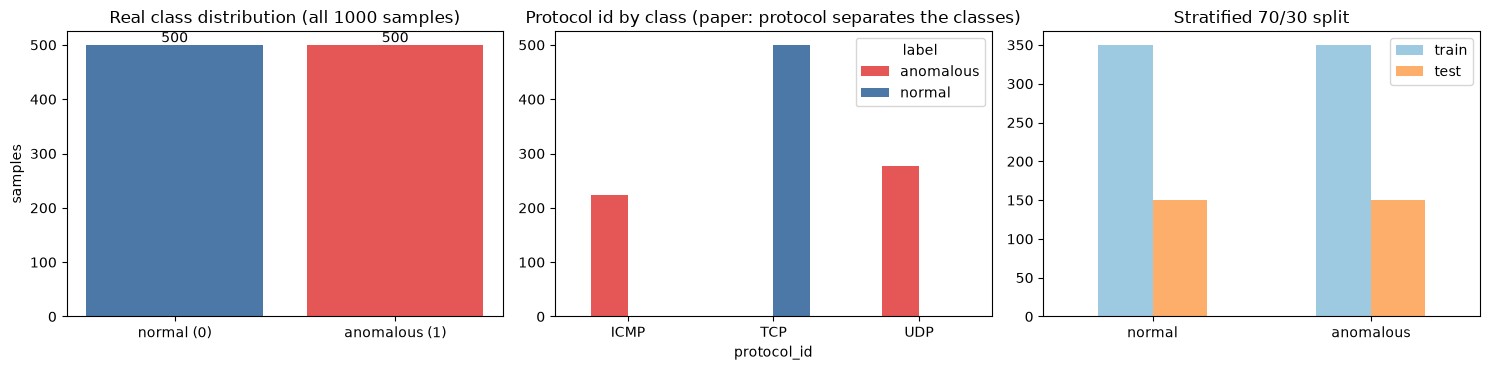

In [5]:
print("shape of the data set      :", df.shape, "(features + label)")
print("feature names              :", FEATURES)
print("label values and counts    :", {int(k): int(v) for k, v in df["label"].value_counts().sort_index().items()}, "(0 = normal, 1 = anomalous)")
print("protocol ids per class     :")
display(pd.crosstab(df["label"].map({0: "normal", 1: "anomalous"}), df["protocol_id"].map(PROTO_NAME)))
print("missing values             :", int(df.isna().sum().sum()), "| negative drop rates:", int((df.packet_drop_rate < 0).sum()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
cnt = df["label"].map({0: "normal (0)", 1: "anomalous (1)"}).value_counts().reindex(["normal (0)", "anomalous (1)"])
axes[0].bar(cnt.index, cnt.values, color=["#4C78A8", "#E45756"]); axes[0].set_title("Real class distribution (all 1000 samples)"); axes[0].set_ylabel("samples")
for i, v in enumerate(cnt.values): axes[0].text(i, v + 5, str(v), ha="center")
sp = pd.crosstab(df["protocol_id"].map(PROTO_NAME), df["label"].map({0: "normal", 1: "anomalous"}))
sp.plot.bar(ax=axes[1], color=["#E45756", "#4C78A8"], rot=0); axes[1].set_title("Protocol id by class (paper: protocol separates the classes)")
tr = pd.DataFrame({"train": np.bincount(D0["ytr"]), "test": np.bincount(D0["yte"])}, index=["normal", "anomalous"])
tr.plot.bar(ax=axes[2], rot=0, color=["#9ecae1", "#fdae6b"]); axes[2].set_title("Stratified 70/30 split")
plt.tight_layout(); plt.show()

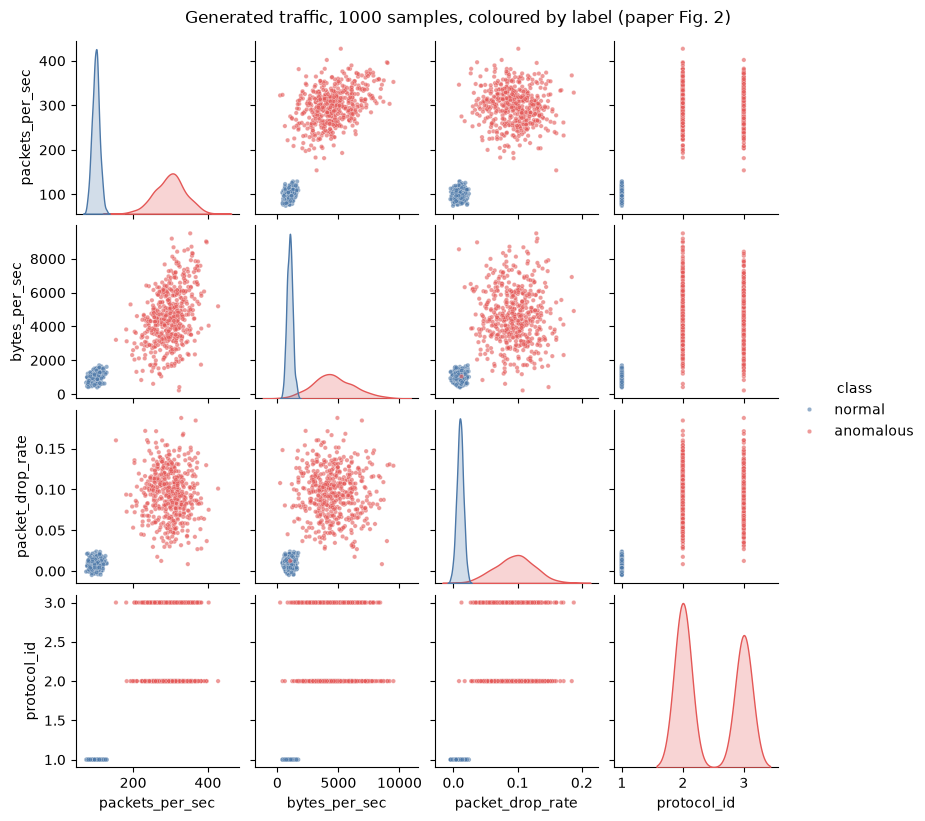

In [6]:
# Paper Figure 2: feature distributions (diagonal) and pairwise scatter, real generated samples coloured by their ground-truth label.
dfp = df.copy(); dfp["class"] = dfp["label"].map({0: "normal", 1: "anomalous"})
g = sns.pairplot(dfp, vars=FEATURES, hue="class", palette={"normal": "#4C78A8", "anomalous": "#E45756"}, plot_kws=dict(s=10, alpha=0.6), height=2.0, corner=False)
g.fig.suptitle("Generated traffic, 1000 samples, coloured by label (paper Fig. 2)", y=1.02); plt.show()

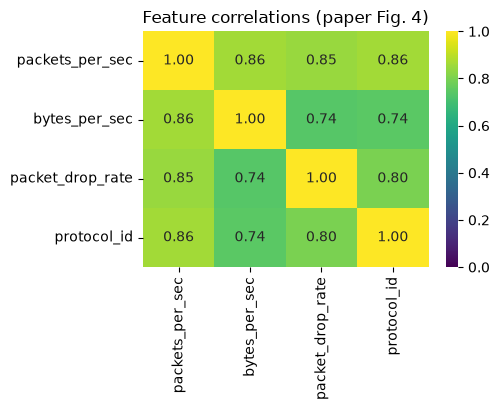

                         quantity  paper  notebook
   corr(packets/s, bytes_per_sec)   0.86      0.86
corr(packets/s, packet_drop_rate)   0.87      0.85
     corr(packets/s, protocol_id)   0.88      0.86


In [7]:
# Paper Figure 4 and claim C3: correlation matrix of the four features.
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(5.2, 4.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax); ax.set_title("Feature correlations (paper Fig. 4)")
plt.tight_layout(); plt.show()
PAPER_CORR = {"bytes_per_sec": 0.86, "packet_drop_rate": 0.87, "protocol_id": 0.88}
CORR_ROWS = [(f"corr(packets/s, {k})", v, round(float(corr.loc["packets_per_sec", k]), 2)) for k, v in PAPER_CORR.items()]
print(pd.DataFrame(CORR_ROWS, columns=["quantity", "paper", "notebook"]).to_string(index=False))

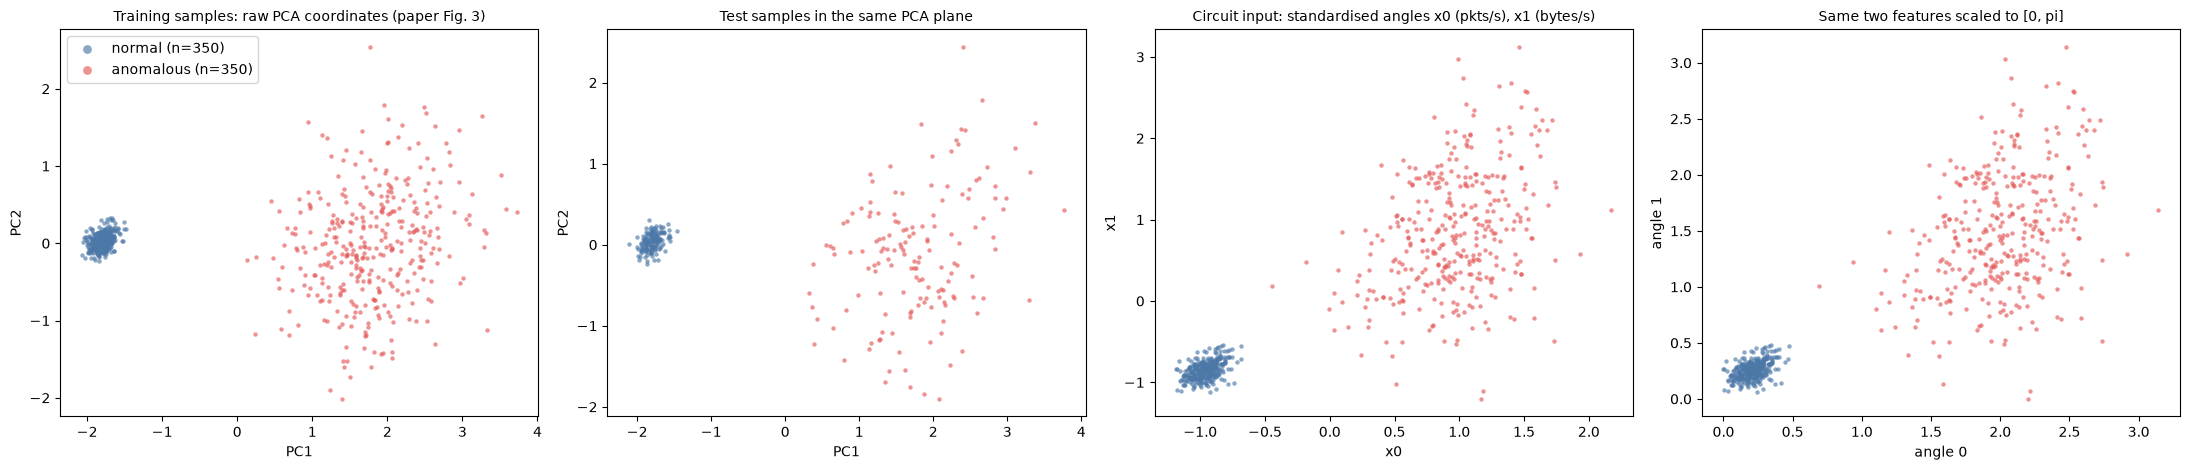

explained variance of PC1 and PC2 (fitted on training data): [0.859 0.067]


In [8]:
# What the classifiers see. Panel 1/2: raw PCA coordinates fitted on the TRAINING split (of the standardised training features), coloured by
# ground-truth label. Panel 3: the standardised values of the first two features = the rotation angles used by the feature maps (the paper does no
# [0, pi] rescaling). Panel 4: the same two angles mapped to [0, pi] for comparison with the other notebooks of this repository.
from sklearn.preprocessing import MinMaxScaler
pca = PCA(n_components=2, random_state=SEED).fit(D0["Xtr"])
Ztr = pca.transform(D0["Xtr"]); Zte = pca.transform(D0["Xte"])
mm = MinMaxScaler((0, np.pi)).fit(D0["Xtr"][:, :2])                    # fitted on training data only
Atr = mm.transform(D0["Xtr"][:, :2])
COL = {0: "#4C78A8", 1: "#E45756"}; NAMEC = {0: "normal", 1: "anomalous"}
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, (A, B, t, xl, yl) in zip(axes, [(Ztr[:, 0], Ztr[:, 1], "Training samples: raw PCA coordinates (paper Fig. 3)", "PC1", "PC2"),
                                          (Zte[:, 0], Zte[:, 1], "Test samples in the same PCA plane", "PC1", "PC2"),
                                          (D0["Xtr"][:, 0], D0["Xtr"][:, 1], "Circuit input: standardised angles x0 (pkts/s), x1 (bytes/s)", "x0", "x1"),
                                          (Atr[:, 0], Atr[:, 1], "Same two features scaled to [0, pi]", "angle 0", "angle 1")]):
    ys = D0["ytr"] if t.startswith(("Training", "Circuit", "Same")) else D0["yte"]
    for c in (0, 1):
        m = ys == c
        ax.scatter(A[m], B[m], s=10, alpha=0.65, c=COL[c], label=f"{NAMEC[c]} (n={m.sum()})", linewidths=0)
    ax.set_title(t, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)
axes[0].legend(markerscale=2)
plt.tight_layout(); plt.show()
print("explained variance of PC1 and PC2 (fitted on training data):", np.round(pca.explained_variance_ratio_, 3))

## Quantum Circuit Architecture

The four classifiers (paper Table 2, Figures 5-12) are built with Qiskit 2.x's function-style circuit library. For each model the cell below creates

* the **feature map** that encodes the four standardised features (`zz_feature_map`, `pauli_feature_map`, `z_feature_map`),
* the **ansatz** (`real_amplitudes` or `n_local` with RY rotations and CZ entanglers),
* the composed circuit `feature map + ansatz` that the QNN executes, and the read-out: `EstimatorQNN` measures the expectation of `Z x Z x Z x Z` (parity of the four
  qubits; class 1 if the value is >= 0), `SamplerQNN` (inside `VQC`) measures all four qubits and maps the 4-bit outcome `k` to class `k mod 2`.

What the paper leaves open and how it is fixed here (all marked `# CHOICE:` in the code): the Pauli strings of `PauliFeatureMap` (Qiskit default `["Z", "ZZ"]`);
the entanglement of the feature maps (default "full") and of the ansatzes (default "reverse_linear" for `RealAmplitudes`, "full" for the CZ `TwoLocal`);
the observable (Qiskit default). Note that with the default Pauli strings the `PauliFeatureMap` is the same encoding circuit as `ZZFeatureMap` (printed below), so VQC-2
differs from VQC-1 in the ansatz, QNN type, loss and shots, not in the feature map.

In [9]:
ARCH = {   # name: (feature map factory, ansatz factory, qnn kind, optimiser name, description)
    "VQC-1": (lambda: zz_feature_map(N_QUBITS, reps=2),     lambda: real_amplitudes(N_QUBITS, reps=2), "est", "SPSA",   "ZZFeatureMap(2) + RealAmplitudes(2), Estimator, SPSA"),
    "VQC-2": (lambda: pauli_feature_map(N_QUBITS, reps=2),  # CHOICE: default paulis ["Z", "ZZ"], entanglement "full"
              lambda: n_local(N_QUBITS, rotation_blocks="ry", entanglement_blocks="cz", reps=2),   # CHOICE: default entanglement "full"
              "smp", "SPSA", "PauliFeatureMap(2) + TwoLocal(RY,CZ;2), Sampler, SPSA"),
    "VQC-3": (lambda: z_feature_map(N_QUBITS, reps=2),      lambda: real_amplitudes(N_QUBITS, reps=3), "est", "ADAM",   "ZFeatureMap(2) + RealAmplitudes(3), Estimator, ADAM"),
    "VQC-4": (lambda: zz_feature_map(N_QUBITS, reps=4),     lambda: real_amplitudes(N_QUBITS, reps=4), "est", "COBYLA", "ZZFeatureMap(4) + RealAmplitudes(4), Estimator, COBYLA"),
}
MODELS = {}
rows = []
for name, (fmf, anf, kind, opt, desc) in ARCH.items():
    fm, an = fmf(), anf()
    qc = QuantumCircuit(N_QUBITS); qc.compose(fm, inplace=True); qc.compose(an, inplace=True)       # the circuit the QNN executes
    MODELS[name] = dict(fm=fm, an=an, qc=qc, kind=kind, opt=opt, desc=desc)
    flat = transpile(qc, basis_gates=["h", "x", "p", "rz", "rx", "ry", "cx", "cz"], optimization_level=0)
    rows.append([name, desc, qc.num_qubits, qc.decompose().depth(), flat.depth(), an.num_parameters, fm.num_parameters,
                 dict(flat.count_ops())])
arch_df = pd.DataFrame(rows, columns=["model", "architecture", "qubits", "depth (decomposed)", "depth (h,p,rz,rx,ry,cx,cz)", "trainable parameters", "input parameters", "gate counts"])
display(arch_df)
same = transpile(pauli_feature_map(N_QUBITS, reps=2), basis_gates=["h", "p", "cx"], optimization_level=0).count_ops() == \
       transpile(zz_feature_map(N_QUBITS, reps=2), basis_gates=["h", "p", "cx"], optimization_level=0).count_ops()
print("PauliFeatureMap(reps=2, default paulis) has the same gate counts as ZZFeatureMap(reps=2):", same)

,model,architecture,qubits,depth (decomposed),"depth (h,p,rz,rx,ry,cx,cz)",trainable parameters,input parameters,gate counts
0,VQC-1,"ZZFeatureMap(2) + RealAmplitudes(2), Estimator...",4,39,39,12,4,"{'cx': 30, 'p': 20, 'ry': 12, 'h': 8}"
1,VQC-2,"PauliFeatureMap(2) + TwoLocal(RY,CZ;2), Sample...",4,53,42,12,4,"{'cx': 24, 'p': 20, 'ry': 12, 'cz': 12, 'h': 8}"
2,VQC-3,"ZFeatureMap(2) + RealAmplitudes(3), Estimator,...",4,15,15,16,4,"{'ry': 16, 'cx': 9, 'h': 8, 'p': 8}"
3,VQC-4,"ZZFeatureMap(4) + RealAmplitudes(4), Estimator...",4,73,73,20,4,"{'cx': 60, 'p': 40, 'ry': 20, 'h': 16}"


PauliFeatureMap(reps=2, default paulis) has the same gate counts as ZZFeatureMap(reps=2): True


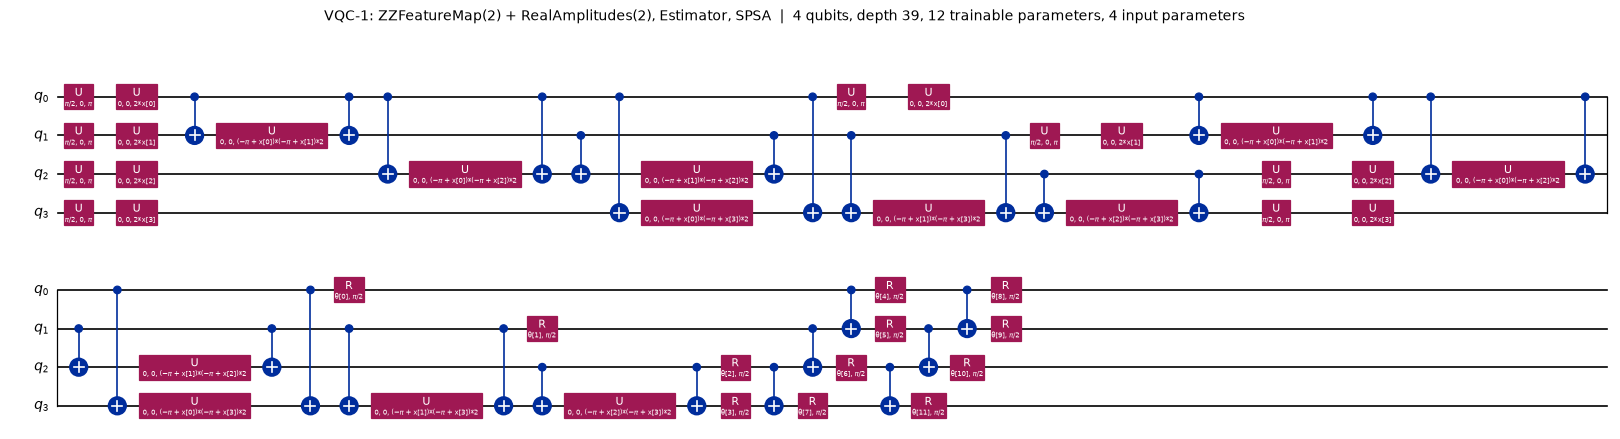

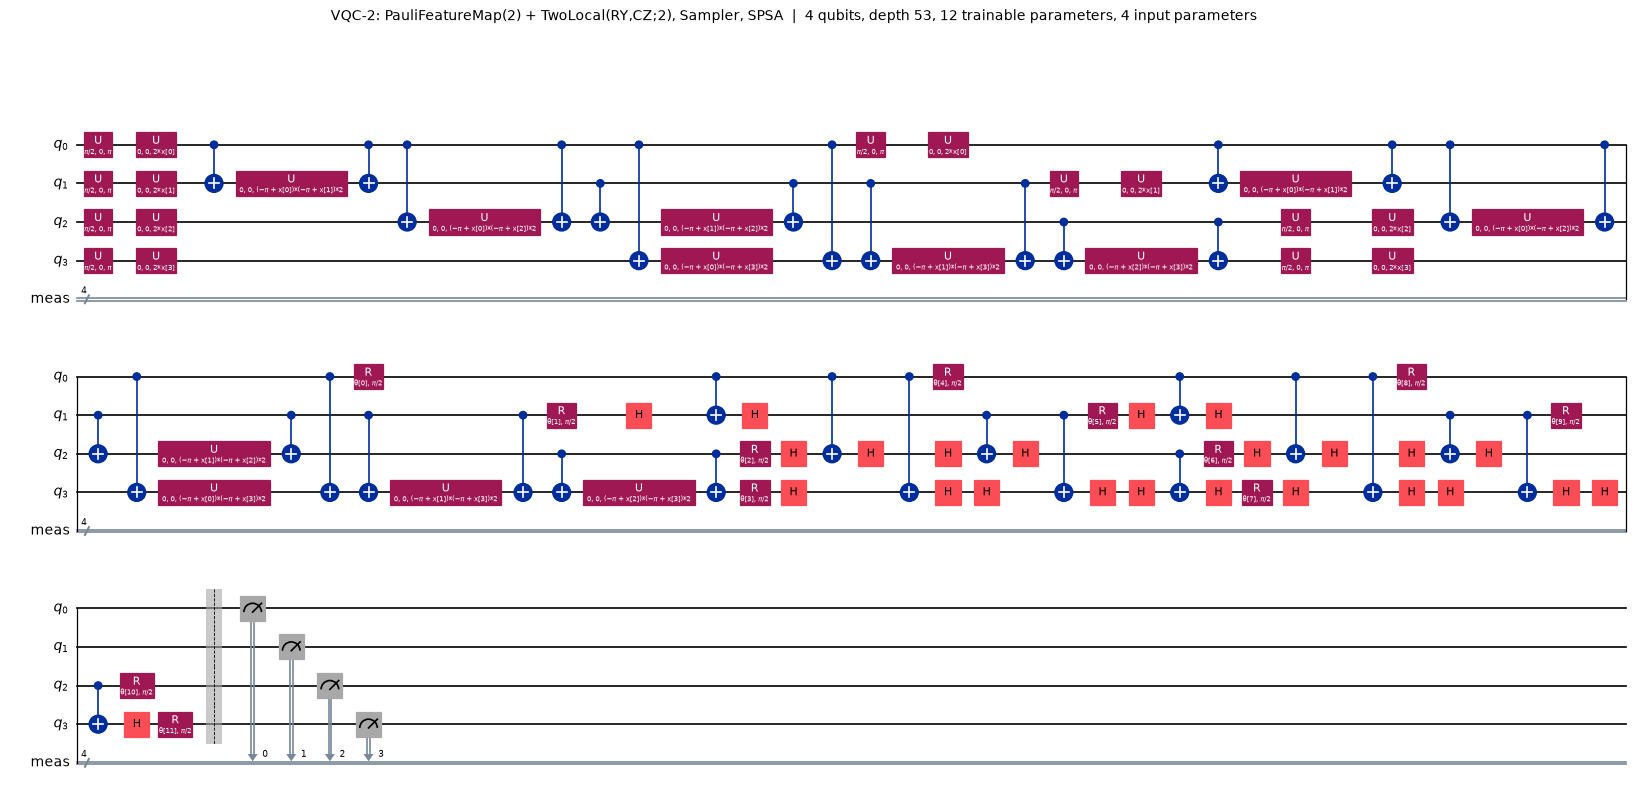

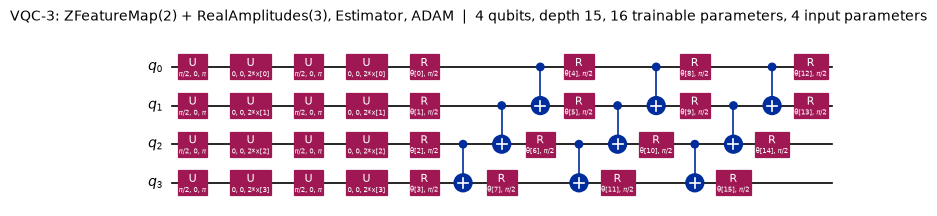

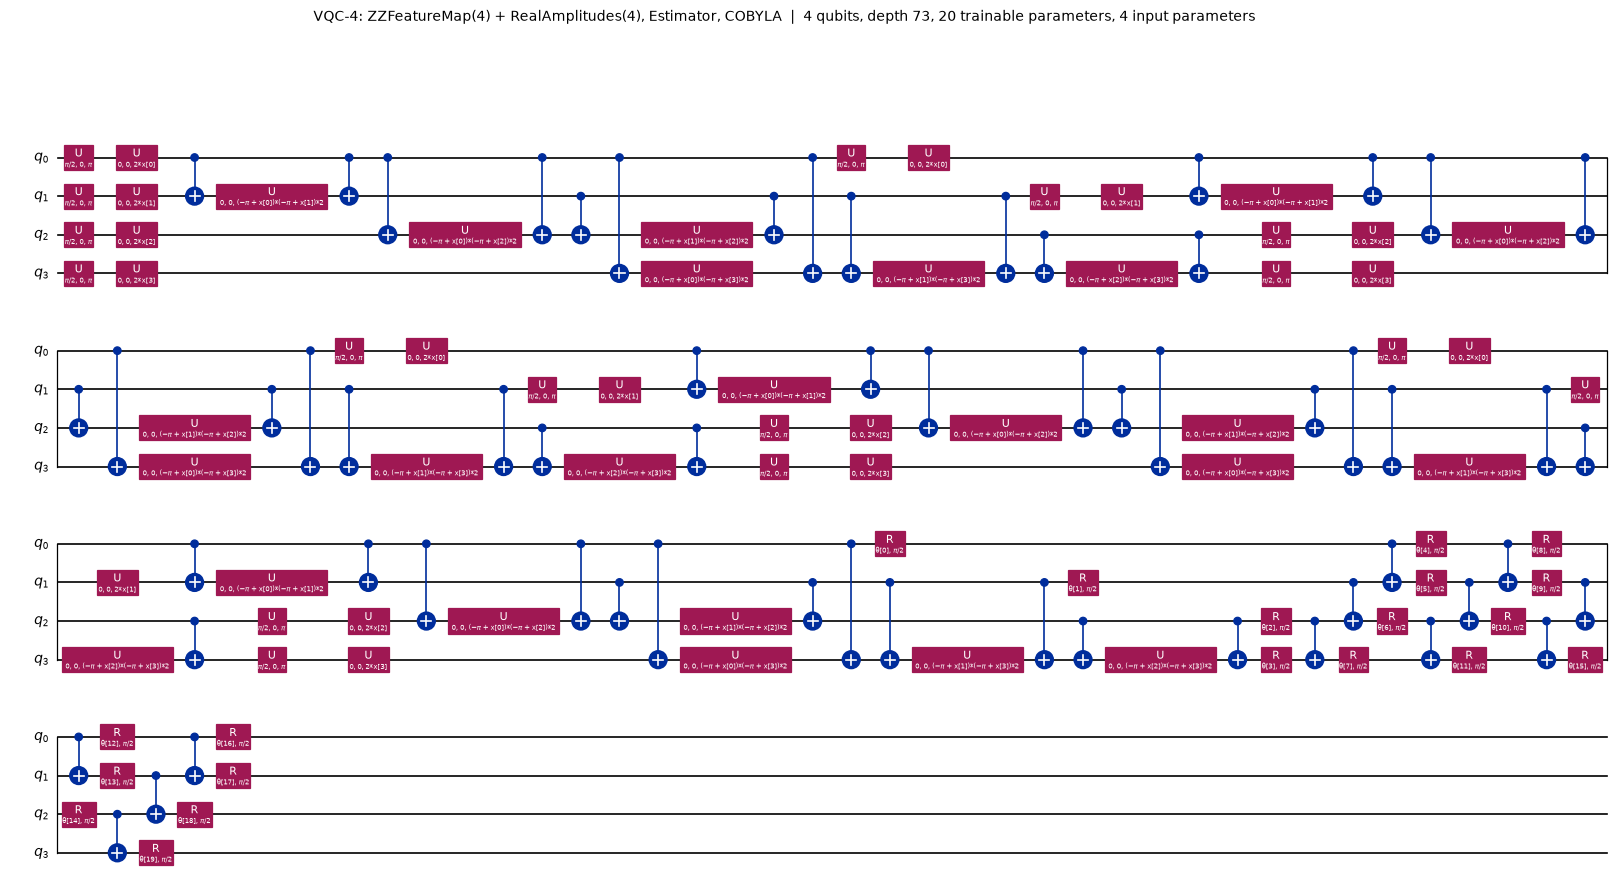

In [10]:
# Figures (paper Figs. 5-12): the circuits that are actually executed. Each drawing is the decomposed feature map + ansatz circuit of the model,
# followed by the read-out (Z^4 expectation for Estimator models, measure_all for the Sampler model).
for name, M in MODELS.items():
    c = M["qc"].decompose()
    if M["kind"] == "smp":
        c = c.copy(); c.measure_all()
    fig = c.draw("mpl", fold=40, style="iqp", scale=0.6)
    fig.suptitle(f"{name}: {M['desc']}  |  {M['qc'].num_qubits} qubits, depth {M['qc'].decompose().depth()}, "
                 f"{M['an'].num_parameters} trainable parameters, {M['fm'].num_parameters} input parameters", y=1.0, fontsize=10)
    display(fig); plt.close(fig)

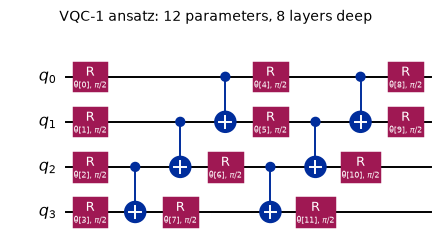

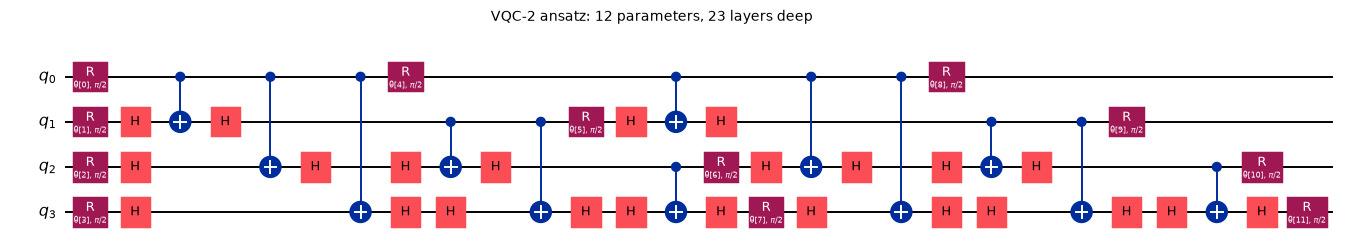

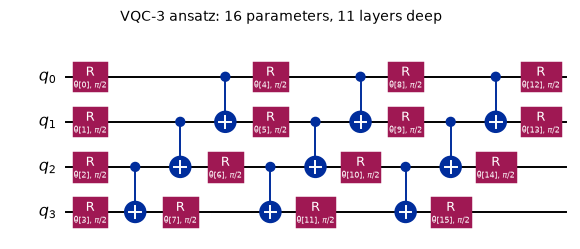

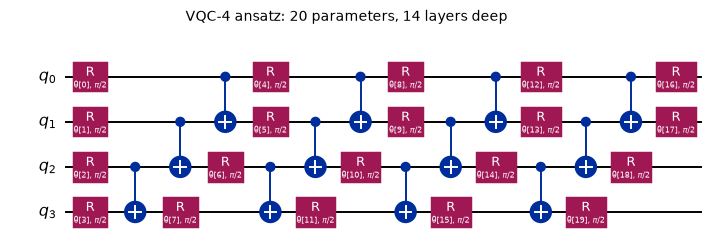

In [11]:
# The ansatz alone for each model (paper Figs. 6, 8, 10, 12), undecomposed one level so that the rotation layers and entanglers are visible.
for name, M in MODELS.items():
    fig = M["an"].decompose().draw("mpl", fold=30, style="iqp", scale=0.7)
    fig.suptitle(f"{name} ansatz: {M['an'].num_parameters} parameters, {M['an'].decompose().depth()} layers deep", y=1.0, fontsize=10)
    display(fig); plt.close(fig)

## 2. A fast exact simulator for these circuits, and tests that it equals Qiskit

Training the real Qiskit classes on 700 samples for 100 iterations is slow on a CPU: one `EstimatorQNN` forward pass of 700 samples took several seconds and one gradient
(parameter shift, `2 x (number of weights)` circuits per sample) minutes, so ADAM would need hours for the baseline and many more for the sensitivity study.
Because all circuits have only four qubits, the same computation can be done exactly with a batched numpy state vector. The simulator below

1. takes the gate list of the Qiskit circuits drawn above (transpiled to `h, x, p, rz, rx, ry, cx, cz`; rotation angles are the symbolic Qiskit expressions, evaluated for the whole batch),
2. applies it to all samples at once (the feature-map state is computed once per data set and cached),
3. gives the `EstimatorQNN` output `<Z Z Z Z>` and the `SamplerQNN` class probabilities, with the same 1,024-shot sampling noise for the Sampler model,
4. computes the parameter-shift gradient of the mean squared error, as `EstimatorQNN.backward` does,
5. feeds the real `SPSA`, `COBYLA` and `ADAM` classes of `qiskit_machine_learning.optimizers`.

It is a shortcut and therefore it is *tested*: below it is compared with `Statevector` of the real circuits, with the real `EstimatorQNN.forward`/`backward`, and in
Section 3 the real `NeuralNetworkClassifier` is trained on a subset and its weights are compared with the simulator's.

In [12]:
# ---------------- fast exact simulator (numpy), built from the gate lists of the Qiskit circuits ----------------

BASIS = ["h", "x", "p", "rz", "rx", "ry", "cx", "cz"]

class FastCircuit:
    """Batched exact state-vector simulator built from the gate list of a real Qiskit circuit."""
    def __init__(self, feature_map, ansatz):
        self.n = feature_map.num_qubits
        self.input_params, self.weight_params = list(feature_map.parameters), list(ansatz.parameters)
        allp = self.input_params + self.weight_params
        self.n_in = len(self.input_params)
        self.ops = []
        for part in (feature_map, ansatz):          # transpiled separately so that the gate order is feature map first
            flat = transpile(part, basis_gates=BASIS, optimization_level=0)
            if part is feature_map:
                self.first_w = len(self.ops) + len(flat.data)
            for inst in flat.data:
                name = inst.operation.name
                q = [flat.find_bit(b).index for b in inst.qubits]
                fn = None
                if inst.operation.params:
                    e = inst.operation.params[0]
                    if hasattr(e, "parameters") and len(e.parameters) > 0:
                        ps = sorted(e.parameters, key=lambda p: allp.index(p))
                        f = sympy.lambdify([sympy.Symbol(p.name) for p in ps], e.sympify(), "numpy")
                        fn = (f, [allp.index(p) for p in ps])
                    else:
                        fn = (None, float(e))
                self.ops.append((name, q, fn))
    def _angle(self, fn, X, w):
        f, idx = fn
        if f is None:
            return idx
        vals = [X[:, j] if j < self.n_in else w[j - self.n_in] for j in idx]
        return f(*vals)

    def _apply(self, S, name, q, ang):
        n = self.n
        ax = 1 + (n - 1 - q[0]) if name not in ("cx", "cz") else None
        if name in ("h", "x", "p", "rz", "rx", "ry"):
            a0 = np.take(S, 0, axis=ax); a1 = np.take(S, 1, axis=ax)
            B = S.shape[0]
            def col(v):
                v = np.asarray(v)
                return v.reshape((-1,) + (1,) * (n - 1)) if v.ndim else v
            if name == "h":
                r = np.sqrt(0.5); n0, n1 = r * (a0 + a1), r * (a0 - a1)
            elif name == "x":
                n0, n1 = a1, a0
            elif name == "p":
                n0, n1 = a0, np.exp(1j * col(ang)) * a1
            elif name == "rz":
                n0, n1 = np.exp(-0.5j * col(ang)) * a0, np.exp(0.5j * col(ang)) * a1
            elif name == "rx":
                c, s = np.cos(col(ang) / 2), np.sin(col(ang) / 2)
                n0, n1 = c * a0 - 1j * s * a1, -1j * s * a0 + c * a1
            else:  # ry
                c, s = np.cos(col(ang) / 2), np.sin(col(ang) / 2)
                n0, n1 = c * a0 - s * a1, s * a0 + c * a1
            return np.stack([n0, n1], axis=ax)
        # two-qubit
        ac, at = 1 + (n - 1 - q[0]), 1 + (n - 1 - q[1])
        idx = [slice(None)] * (n + 1)
        if name == "cz":
            S = S.copy(); idx[ac] = 1; idx[at] = 1
            S[tuple(idx)] *= -1
            return S
        S = S.copy(); idx[ac] = 1
        sub = S[tuple(idx)]
        at2 = at if at < ac else at - 1
        S[tuple(idx)] = np.flip(sub, axis=at2)
        return S

    def encode(self, X):
        """State after the feature map (independent of the weights): shape (B, 2,...,2)."""
        B = X.shape[0]
        S = np.zeros((B,) + (2,) * self.n, dtype=complex); S[(slice(None),) + (0,) * self.n] = 1
        for name, q, fn in self.ops[:self.first_w]:
            S = self._apply(S, name, q, None if fn is None else self._angle(fn, X, None))
        return S

    def run(self, S0, X, w):
        S = S0
        for name, q, fn in self.ops[self.first_w:]:
            S = self._apply(S, name, q, None if fn is None else self._angle(fn, X, w))
        return S.reshape(S.shape[0], -1)

    def probs(self, S0, X, w):
        return np.abs(self.run(S0, X, w)) ** 2

    def parity_expectation(self, S0, X, w):
        p = self.probs(S0, X, w)
        k = np.arange(p.shape[1])
        sign = 1 - 2 * (np.array([bin(i).count("1") for i in k]) % 2)
        return p @ sign

In [13]:
for name, M in MODELS.items():
    M["fc"] = FastCircuit(M["fm"], M["an"])

# ---- test 1: output probabilities equal Qiskit's Statevector of the composed circuit for random inputs and weights
r_ = np.random.default_rng(0)
for name, M in MODELS.items():
    X = r_.normal(size=(6, N_QUBITS)); w = r_.uniform(0, 2 * np.pi, M["an"].num_parameters)
    P = M["fc"].probs(M["fc"].encode(X), X, w)
    for i in range(len(X)):
        b = M["qc"].assign_parameters({**dict(zip(M["fm"].parameters, X[i])), **dict(zip(M["an"].parameters, w))})
        assert np.allclose(P[i], Statevector(b).probabilities(), atol=1e-10), name
print("test 1 passed: simulator probabilities == Qiskit Statevector for the four circuits (6 random inputs each, atol 1e-10)")

# ---- test 2: the real EstimatorQNN (default StatevectorEstimator, observable Z^4) gives the same forward values and gradients
for name in ["VQC-1", "VQC-3", "VQC-4"]:
    M = MODELS[name]
    qnn = EstimatorQNN(circuit=M["qc"], input_params=M["fm"].parameters, weight_params=M["an"].parameters)
    X = r_.normal(size=(3, N_QUBITS)); w = r_.uniform(0, 2 * np.pi, M["an"].num_parameters)
    S0 = M["fc"].encode(X)
    f_fast = M["fc"].parity_expectation(S0, X, w)
    assert np.allclose(qnn.forward(X, w).ravel(), f_fast, atol=1e-10), name
    _, gw = qnn.backward(X, w)                                           # shape (3, 1, n_weights)
    g_fast = np.zeros((3, len(w)))
    for j in range(len(w)):
        e = np.zeros(len(w)); e[j] = np.pi / 2
        g_fast[:, j] = (M["fc"].parity_expectation(S0, X, w + e) - M["fc"].parity_expectation(S0, X, w - e)) / 2
    assert np.allclose(gw[:, 0, :], g_fast, atol=1e-9), name
    print(f"test 2 passed for {name}: EstimatorQNN forward and parameter-shift gradient == simulator (max grad diff {np.abs(gw[:,0,:]-g_fast).max():.1e})")

test 1 passed: simulator probabilities == Qiskit Statevector for the four circuits (6 random inputs each, atol 1e-10)


test 2 passed for VQC-1: EstimatorQNN forward and parameter-shift gradient == simulator (max grad diff 6.0e-14)


test 2 passed for VQC-3: EstimatorQNN forward and parameter-shift gradient == simulator (max grad diff 1.1e-15)


test 2 passed for VQC-4: EstimatorQNN forward and parameter-shift gradient == simulator (max grad diff 9.4e-14)


In [14]:
SIGN = lambda n: 1 - 2 * (np.array([bin(i).count("1") for i in range(2 ** n)]) % 2)

def init_point(seed, n_params):
    algorithm_globals.random_seed = seed                 # Qiskit's default initial point of a classifier: uniform in [0, 1)
    return algorithm_globals.random.random(n_params)

def weighted_metrics(y, p):
    return dict(acc=100 * accuracy_score(y, p), prec=100 * precision_score(y, p, average="weighted", zero_division=0),
                rec=100 * recall_score(y, p, average="weighted", zero_division=0), f1=100 * f1_score(y, p, average="weighted", zero_division=0),
                cm=confusion_matrix(y, p, labels=[0, 1]))

def build_optimizer(name, maxiter, lr=None, callback=None):
    if name == "SPSA":   return SPSA(maxiter=maxiter, callback=callback)
    if name == "COBYLA": return COBYLA(maxiter=maxiter)
    if name == "ADAM":   return ADAM(maxiter=maxiter, callback=callback, **({} if lr is None else dict(lr=lr)))

def train_fast(name, Xtr, ytr, maxiter, seed, lr=None, x0=None):
    # Trains model `name` with the simulator. Returns weights, per-iteration loss history and bookkeeping.
    M = MODELS[name]; fc, nw = M["fc"], M["an"].num_parameters
    S0 = fc.encode(Xtr); hist = []
    x0 = init_point(seed, nw) if x0 is None else x0.copy()
    shot_rng = np.random.default_rng(seed)
    if M["kind"] == "est":
        t = 2.0 * ytr - 1.0                                              # CHOICE: labels as -1/+1 (the sign of the output is the class)
        f = lambda w: fc.parity_expectation(S0, Xtr, w)
        obj = lambda w: float(np.mean((f(w) - t) ** 2))                   # mean squared error (L2Loss / n), as BinaryObjectiveFunction
        def jac(w):
            fw, g = f(w), np.zeros(nw)
            for j in range(nw):                                          # parameter shift, exact for RY/RX/RZ rotations that occur once
                e = np.zeros(nw); e[j] = np.pi / 2
                g[j] = np.mean(2 * (fw - t) * (fc.parity_expectation(S0, Xtr, w + e) - fc.parity_expectation(S0, Xtr, w - e)) / 2)
            return g
    else:
        Y = np.eye(2)[ytr]; loss = CrossEntropyLoss()
        def class_probs(S, X, w):
            p1 = fc.probs(S, X, w)[:, 1::2].sum(axis=1)                    # parity read-out: class = outcome mod 2
            k = shot_rng.binomial(SHOTS, np.clip(p1, 0, 1)) / SHOTS        # SHOTS-shot estimate, as StatevectorSampler
            return np.c_[1 - k, k]
        obj = lambda w: float(np.sum(loss(class_probs(S0, Xtr, w), Y)) / len(Xtr))
        jac = None
    evals = []
    def counted(w):
        v = obj(w); evals.append(v); return v
    if M["opt"] == "SPSA":
        cb = lambda nfev, x, fx, step, acc: hist.append(fx)
        res = build_optimizer("SPSA", maxiter, callback=cb).minimize(counted, x0)
    elif M["opt"] == "ADAM":
        cb = lambda t_, x, fx: hist.append(fx)
        res = build_optimizer("ADAM", maxiter, lr=lr, callback=cb).minimize(counted, x0, jac=jac)
    else:
        res = build_optimizer("COBYLA", maxiter).minimize(counted, x0); hist = list(evals)
    w = np.asarray(res.x)
    return dict(w=w, hist=np.array(hist), nfev=len(evals), final_loss=float(res.fun), x0=x0)

def predict_fast(name, w, X, seed):
    M = MODELS[name]; fc = M["fc"]; S = fc.encode(X)
    if M["kind"] == "est":
        return (fc.parity_expectation(S, X, w) >= 0).astype(int)           # paper: output >= 0 -> class 1
    p1 = fc.probs(S, X, w)[:, 1::2].sum(axis=1)
    k = np.random.default_rng(seed + 1000).binomial(SHOTS, np.clip(p1, 0, 1)) / SHOTS
    return (k > 0.5).astype(int)

def run_model(name, D, maxiter=MAXITER, lr=None):
    t0 = time.time()
    r = train_fast(name, D["Xtr"], D["ytr"], maxiter, D["seed"], lr=lr)
    pred = predict_fast(name, r["w"], D["Xte"], D["seed"])
    r.update(weighted_metrics(D["yte"], pred)); r["pred"] = pred; r["seconds"] = time.time() - t0
    r["train_acc"] = 100 * accuracy_score(D["ytr"], predict_fast(name, r["w"], D["Xtr"], D["seed"]))
    return r
print("training and prediction helpers defined")

training and prediction helpers defined


## 3. The real Qiskit classes on a subset, side by side with the simulator

Before the simulator is used for the paper-sized runs, the **real** `NeuralNetworkClassifier(EstimatorQNN)` (VQC-1, VQC-3, VQC-4) and the real Qiskit `VQC` with `SamplerQNN`
(VQC-2) are trained on a small random subset of the training data, from the same initial point and with the same optimiser, and compared with the simulator. For the three exact models
(no shot noise) both implementations use the same optimiser class, the same random stream (`algorithm_globals`) and the same objective, so the final weights must agree
to numerical precision. For VQC-2 the shot noise streams differ, so only the forward pass is compared (within the binomial standard error) and the final losses are shown.

In [15]:
sub_idx = np.random.default_rng(SEED).choice(len(D0["ytr"]), CHK_N_TRAIN, replace=False)
Xs, ys = D0["Xtr"][sub_idx], D0["ytr"][sub_idx]
print(f"subset: {len(ys)} training samples; iterations: {CHK_ITERS}")
rows = []
for name in ["VQC-1", "VQC-4", "VQC-3", "VQC-2"]:
    M = MODELS[name]; it = CHK_ITERS[M["opt"]]
    x0 = init_point(SEED, M["an"].num_parameters)
    t0 = time.time()
    if M["kind"] == "est":
        qnn = EstimatorQNN(circuit=M["qc"], input_params=M["fm"].parameters, weight_params=M["an"].parameters)
        algorithm_globals.random_seed = SEED; _ = algorithm_globals.random.random(M["an"].num_parameters)    # same random-stream state as the simulator run
        clf = NeuralNetworkClassifier(neural_network=qnn, loss="squared_error", optimizer=build_optimizer(M["opt"], it), initial_point=x0.copy())
        clf.fit(Xs, 2.0 * ys - 1.0)
        w_real = np.asarray(clf.fit_result.x)
        t_real = time.time() - t0
        algorithm_globals.random_seed = SEED; _ = algorithm_globals.random.random(M["an"].num_parameters)
        r = train_fast(name, Xs, ys, it, SEED, x0=x0)
        dw = float(np.abs(w_real - r["w"]).max())
        rows.append([name, M["opt"], it, "exact", float(clf.fit_result.fun), r["final_loss"], dw, t_real])
        assert dw < 1e-6, f"{name}: real and simulated weights differ by {dw}"
    else:
        vqc = VQC(feature_map=M["fm"], ansatz=M["an"], optimizer=build_optimizer("SPSA", it), loss="cross_entropy",
                  sampler=StatevectorSampler(default_shots=SHOTS, seed=SEED), initial_point=x0.copy())
        vqc.fit(Xs, ys)
        t_real = time.time() - t0
        r = train_fast(name, Xs, ys, it, SEED, x0=x0)
        # forward-pass check of the real SamplerQNN against the simulator's exact class probabilities (random weights)
        wtest = np.random.default_rng(1).uniform(0, 2 * np.pi, M["an"].num_parameters)
        Xq = D0["Xte"][:12]
        real_p = vqc.neural_network.forward(Xq, wtest)
        exact_p1 = M["fc"].probs(M["fc"].encode(Xq), Xq, wtest)[:, 1::2].sum(axis=1)
        z = np.abs(real_p[:, 1] - exact_p1) / np.sqrt(np.clip(exact_p1 * (1 - exact_p1), 1e-3, None) / SHOTS)
        assert z.max() < 5, z.max()
        rows.append([name, M["opt"], it, f"shot noise (max dev {z.max():.1f} sigma)", float(vqc.fit_result.fun), r["final_loss"], np.nan, t_real])
chk = pd.DataFrame(rows, columns=["model", "optimiser", "iterations", "determinism", "final loss: real Qiskit", "final loss: simulator", "max |weight difference|", "real Qiskit seconds"])
display(chk)
print("Real Qiskit and simulator agree: weights of VQC-1/3/4 equal to < 1e-6; VQC-2 forward pass within shot noise.")

subset: 30 training samples; iterations: {'SPSA': 10, 'COBYLA': 15, 'ADAM': 4}


,model,optimiser,iterations,determinism,final loss: real Qiskit,final loss: simulator,max |weight difference|,real Qiskit seconds
0,VQC-1,SPSA,10,exact,0.841363,0.841363,6.883383e-14,29.445401
1,VQC-4,COBYLA,15,exact,0.783609,0.783609,0.000000e+00,18.831147
2,VQC-3,ADAM,4,exact,0.782215,0.782215,1.110223e-16,36.516400
3,VQC-2,SPSA,10,shot noise (max dev 2.2 sigma),0.734816,0.688717,NaN,59.269881


Real Qiskit and simulator agree: weights of VQC-1/3/4 equal to < 1e-6; VQC-2 forward pass within shot noise.


## 4. Baseline experiment (paper Section 4.1, Table 5, Figures 13-20)

Baseline parameters (paper Table 4): seed 42, 1,000 samples, anomaly ratio 0.5, test size 0.3, 100 optimiser iterations. Each model is trained once with the paper's seed
(the paper shows one run per model), then the whole experiment is repeated for other seeds to show the run-to-run spread, which on 300 test points is as large as the
2-point verdict tolerance.

*Note on the VQC-3 learning rate.* The paper does not state it. The primary VQC-3 result uses the library default (0.001). The row **VQC-3\*** is an extension: the learning rate
is chosen from {0.001, 0.01, 0.1} on a 25 % validation split *of the training data* of the baseline run (the test set is never used) and then reused for every other VQC-3\* run.

In [16]:
# --- learning-rate selection for VQC-3* on a validation split of the baseline TRAINING data (CHOICE; the test set is not touched)
Xa, Xv, ya, yv = train_test_split(D0["Xtr"], D0["ytr"], test_size=0.25, stratify=D0["ytr"], random_state=SEED)
lr_rows = []
for lr in ADAM_LRS:
    r = train_fast("VQC-3", Xa, ya, MAXITER, SEED, lr=lr)
    lr_rows.append([lr, 100 * accuracy_score(yv, predict_fast("VQC-3", r["w"], Xv, SEED)), r["final_loss"]])
lr_df = pd.DataFrame(lr_rows, columns=["ADAM learning rate", "validation accuracy %", "training MSE"])
display(lr_df.round(3))
LR_TUNED = float(lr_df.sort_values("validation accuracy %", ascending=False).iloc[0, 0])
print("learning rate selected on the validation split:", LR_TUNED)

# --- the baseline run of all models with seed 42
BASE = {}
for name in ARCH:
    BASE[name] = run_model(name, D0)
BASE["VQC-3*"] = run_model("VQC-3", D0, lr=LR_TUNED)
base_tab = pd.DataFrame({k: dict(accuracy=v["acc"], precision=v["prec"], recall=v["rec"], F1=v["f1"], train_acc=v["train_acc"], final_loss=v["final_loss"],
                                 iterations=len(v["hist"]), evaluations=v["nfev"], seconds=v["seconds"]) for k, v in BASE.items()}).T
print("Baseline, seed 42 (weighted-average metrics in %):")
display(base_tab.round(2))

,ADAM learning rate,validation accuracy %,training MSE
0,0.001,73.143,0.711
1,0.010,71.429,0.566
2,0.100,81.143,0.456


learning rate selected on the validation split: 0.1


Baseline, seed 42 (weighted-average metrics in %):


,accuracy,precision,recall,F1,train_acc,final_loss,iterations,evaluations,seconds
VQC-1,69.67,77.22,69.67,67.41,71.86,0.74,100.0,351.0,3.82
VQC-2,74.33,82.44,74.33,72.62,76.29,0.70,100.0,351.0,4.56
VQC-3,72.33,82.19,72.33,70.04,70.14,0.71,100.0,101.0,45.50
VQC-4,69.67,72.47,69.67,68.69,75.14,0.73,100.0,100.0,2.87
VQC-3*,83.00,87.31,83.00,82.49,85.00,0.46,100.0,101.0,54.77


In [17]:
# Paper Table 5 next to the notebook (seed 42).
PAPER_T5 = {"VQC-1": (72.0, 80.2, 72.0, 70.0), "VQC-2": (57.3, 77.0, 57.3, 47.8), "VQC-3": (84.7, 88.3, 84.7, 84.3), "VQC-4": (89.0, 89.8, 89.0, 88.9)}
rows = []
for k, p in PAPER_T5.items():
    b = BASE[k]; rows.append([k, "paper"] + list(p)); rows.append([k, "notebook"] + [round(b[m], 1) for m in ("acc", "prec", "rec", "f1")])
display(pd.DataFrame(rows, columns=["model", "source", "accuracy", "precision", "recall", "F1"]).set_index(["model", "source"]))

accuracy  precision  recall    F1
model source                                     
VQC-1 paper         72.0       80.2    72.0  70.0
      notebook      69.7       77.2    69.7  67.4
VQC-2 paper         57.3       77.0    57.3  47.8
      notebook      74.3       82.4    74.3  72.6
VQC-3 paper         84.7       88.3    84.7  84.3
      notebook      72.3       82.2    72.3  70.0
VQC-4 paper         89.0       89.8    89.0  88.9
      notebook      69.7       72.5    69.7  68.7

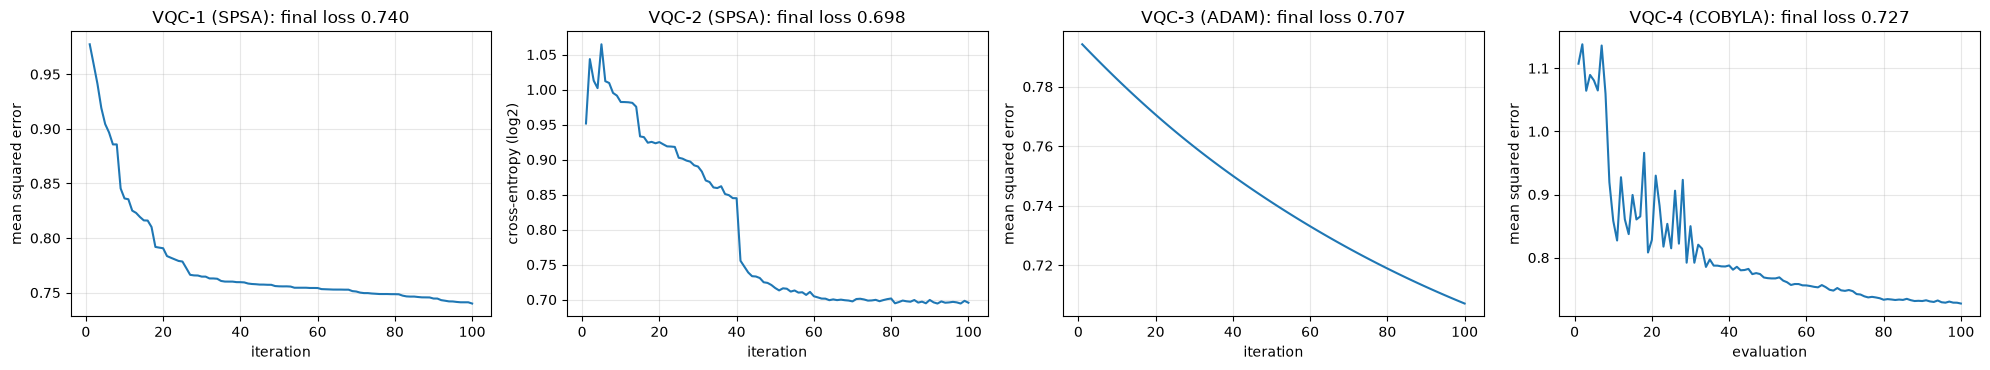

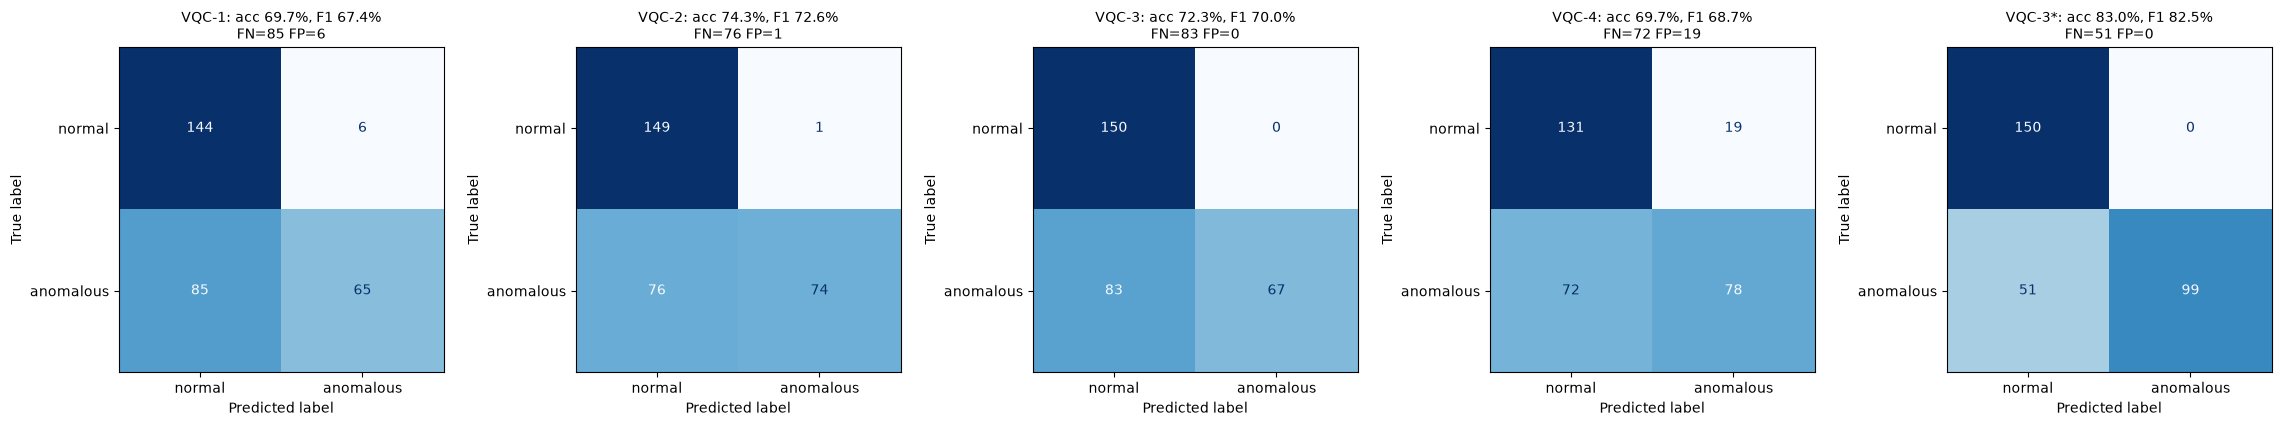

In [18]:
# Loss curves (paper Figs. 13, 15, 17, 19): training loss per optimiser iteration (SPSA, ADAM) or per function evaluation (COBYLA).
fig, axes = plt.subplots(1, 4, figsize=(20, 3.8))
LOSSNAME = {"est": "mean squared error", "smp": "cross-entropy (log2)"}
for ax, name in zip(axes, ARCH):
    h = BASE[name]["hist"]; ax.plot(np.arange(1, len(h) + 1), h, color="#1f77b4")
    ax.set_title(f"{name} ({MODELS[name]['opt']}): final loss {BASE[name]['final_loss']:.3f}"); ax.set_xlabel("iteration" if MODELS[name]["opt"] != "COBYLA" else "evaluation")
    ax.set_ylabel(LOSSNAME[MODELS[name]["kind"]]); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Confusion matrices (paper Figs. 14, 16, 18, 20), anomalous = positive class
fig, axes = plt.subplots(1, 5, figsize=(23, 4.2))
for ax, name in zip(axes, list(BASE)):
    ConfusionMatrixDisplay(BASE[name]["cm"], display_labels=["normal", "anomalous"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    tn, fp, fn, tp = BASE[name]["cm"].ravel()
    ax.set_title(f"{name}: acc {BASE[name]['acc']:.1f}%, F1 {BASE[name]['f1']:.1f}%\nFN={fn} FP={fp}", fontsize=10)
plt.tight_layout(); plt.show()

### Classical baselines on identical inputs (paper Section 4.4, Table 11, Figure 23)

SVM (RBF) and Random Forest are trained on exactly the same standardised training split and evaluated on the same test split.

Table 11 recomputed (seed 42; paper: SVM and RF 100.0 on every metric):


,accuracy,precision,recall,F1
model,,,,
VQC-1,69.7,77.2,69.7,67.4
VQC-2,74.3,82.4,74.3,72.6
VQC-3,72.3,82.2,72.3,70.0
VQC-3*,83.0,87.3,83.0,82.5
VQC-4 (deep),69.7,72.5,69.7,68.7
SVM (RBF),100.0,100.0,100.0,100.0
Random Forest,100.0,100.0,100.0,100.0


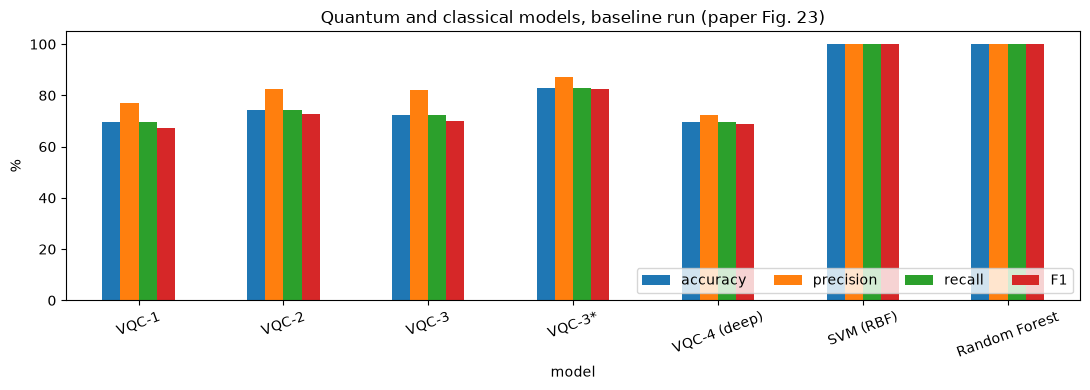

In [19]:
def run_classical(D):
    out = {}
    for nm, mdl in [("SVM (RBF)", SVC(kernel="rbf")), ("Random Forest", RandomForestClassifier(random_state=D["seed"]))]:
        t0 = time.time(); mdl.fit(D["Xtr"], D["ytr"]); p = mdl.predict(D["Xte"])
        out[nm] = dict(weighted_metrics(D["yte"], p), seconds=time.time() - t0, pred=p)
    return out
CLASSICAL = run_classical(D0)
rows = []
for k in ["VQC-1", "VQC-2", "VQC-3", "VQC-3*", "VQC-4"]:
    rows.append([k + (" (deep)" if k == "VQC-4" else ""), BASE[k]["acc"], BASE[k]["prec"], BASE[k]["rec"], BASE[k]["f1"]])
for k, v in CLASSICAL.items():
    rows.append([k, v["acc"], v["prec"], v["rec"], v["f1"]])
t11 = pd.DataFrame(rows, columns=["model", "accuracy", "precision", "recall", "F1"]).set_index("model")
print("Table 11 recomputed (seed 42; paper: SVM and RF 100.0 on every metric):")
display(t11.round(1))
ax = t11.plot.bar(figsize=(11, 4), rot=20, ylim=(0, 105)); ax.set_ylabel("%"); ax.set_title("Quantum and classical models, baseline run (paper Fig. 23)"); ax.legend(loc="lower right", ncol=4)
plt.tight_layout(); plt.show()

### Misclassification analysis of VQC-4 (paper Section 4.3, Figures 21-22)

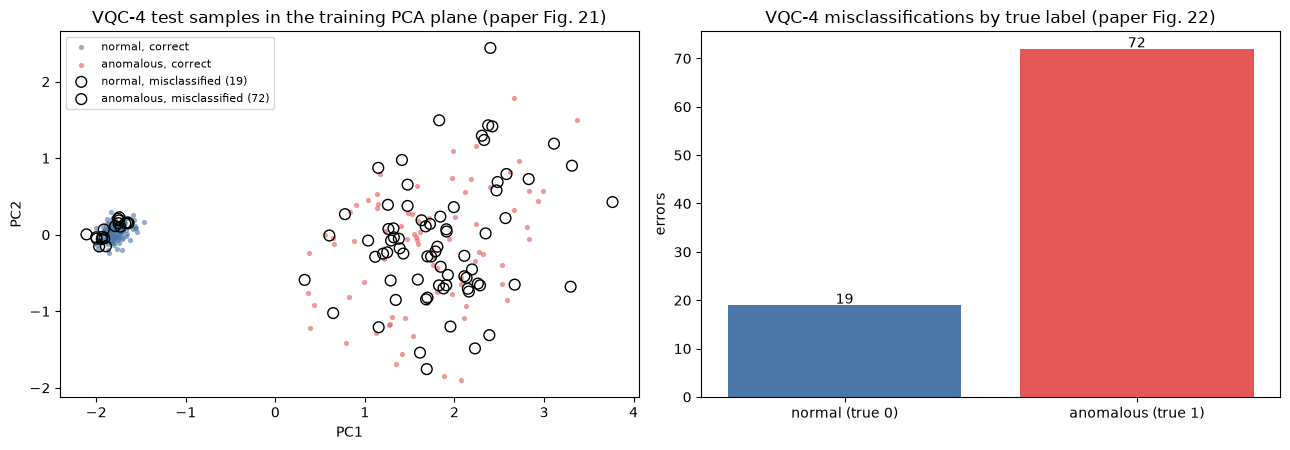

errors by true label: {'normal (true 0)': 19, 'anomalous (true 1)': 72} | total errors: 91 of 300


In [20]:
# Figures 21 and 22: where VQC-4 errs. PCA is fitted on the training split; the test points are drawn, errors are marked.
pred = BASE["VQC-4"]["pred"]; yte = D0["yte"]; wrong = pred != yte
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for c in (0, 1):
    m = (yte == c) & ~wrong
    axes[0].scatter(Zte[m, 0], Zte[m, 1], s=14, c=COL[c], alpha=0.6, label=f"{NAMEC[c]}, correct", linewidths=0)
for c in (0, 1):
    m = (yte == c) & wrong
    axes[0].scatter(Zte[m, 0], Zte[m, 1], s=60, facecolors="none", edgecolors="k", marker="o", label=f"{NAMEC[c]}, misclassified ({m.sum()})" if m.any() else None)
axes[0].set_title("VQC-4 test samples in the training PCA plane (paper Fig. 21)"); axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend(fontsize=8)
err = pd.Series({"normal (true 0)": int(((yte == 0) & wrong).sum()), "anomalous (true 1)": int(((yte == 1) & wrong).sum())})
axes[1].bar(err.index, err.values, color=["#4C78A8", "#E45756"]); axes[1].set_title("VQC-4 misclassifications by true label (paper Fig. 22)"); axes[1].set_ylabel("errors")
for i, v in enumerate(err.values): axes[1].text(i, v + 0.3, str(v), ha="center")
plt.tight_layout(); plt.show()
print("errors by true label:", err.to_dict(), "| total errors:", int(wrong.sum()), "of", len(yte))

## 5. Run-to-run spread over seeds (extension) and sensitivity to the seed (paper Section 4.2.1, Table 6)

Changing the seed changes the generated data, the split and the initial weights (and the shot noise), which is the paper's "random initialisation" experiment with seeds 7 and 100.
Further seeds only add statistics. The classical models are repeated for every seed as well.

In [21]:
SEEDS = [SEED] + EXTRA_SEEDS
ALL = {}     # (condition, seed) -> {model: result}
def run_condition(cond, seed, n=N_SAMPLES, r=ANOMALY_RATIO, ts=TEST_SIZE, it=MAXITER):
    D = make_data(seed, n, r, ts); res = {}
    for name in ARCH:
        res[name] = run_model(name, D, maxiter=it)
    res["VQC-3*"] = run_model("VQC-3", D, maxiter=it, lr=LR_TUNED)
    res.update(run_classical(D))
    ALL[(cond, seed)] = res
    return res

ALL[("baseline", SEED)] = dict(BASE, **CLASSICAL)
for sd in EXTRA_SEEDS:
    t0 = time.time(); run_condition("baseline", sd); print(f"seed {sd}: done in {time.time()-t0:.0f} s")

MODEL_ROWS = ["VQC-1", "VQC-2", "VQC-3", "VQC-3*", "VQC-4", "SVM (RBF)", "Random Forest"]
rows = []
for m in MODEL_ROWS:
    a = np.array([ALL[("baseline", sd)][m]["acc"] for sd in SEEDS]); f = np.array([ALL[("baseline", sd)][m]["f1"] for sd in SEEDS])
    rows.append([m] + [round(ALL[("baseline", sd)][m]["acc"], 1) for sd in SEEDS] + [f"{a.mean():.1f} +- {a.std(ddof=1):.1f}", f"{f.mean():.1f} +- {f.std(ddof=1):.1f}"])
spread = pd.DataFrame(rows, columns=["model"] + [f"acc seed {sd}" for sd in SEEDS] + ["accuracy mean +- std", "F1 mean +- std"]).set_index("model")
print(f"Accuracy (%) of the baseline configuration for {len(SEEDS)} seeds (seed 42 and the paper's 7, 100 first):")
display(spread)

seed 7: done in 98 s


seed 100: done in 86 s


seed 1: done in 80 s


seed 2: done in 109 s


seed 3: done in 100 s
Accuracy (%) of the baseline configuration for 6 seeds (seed 42 and the paper's 7, 100 first):


,acc seed 42,acc seed 7,acc seed 100,acc seed 1,acc seed 2,acc seed 3,accuracy mean +- std,F1 mean +- std
model,,,,,,,,
VQC-1,69.7,74.7,71.7,74.0,69.0,76.3,72.6 +- 2.9,70.7 +- 3.3
VQC-2,74.3,74.3,72.7,73.3,73.0,65.0,72.1 +- 3.6,70.3 +- 3.2
VQC-3,72.3,68.0,64.0,64.0,74.0,72.7,69.2 +- 4.5,67.3 +- 3.9
VQC-3*,83.0,84.7,87.0,81.7,89.7,89.3,85.9 +- 3.3,85.6 +- 3.5
VQC-4,69.7,74.0,71.7,74.0,72.7,72.3,72.4 +- 1.6,71.8 +- 1.9
SVM (RBF),100.0,100.0,100.0,100.0,100.0,100.0,100.0 +- 0.0,100.0 +- 0.0
Random Forest,100.0,100.0,100.0,100.0,100.0,100.0,100.0 +- 0.0,100.0 +- 0.0


In [22]:
PAPER_T6 = {"VQC-1": {7: (72.7, 70.7), 100: (72.7, 70.6)}, "VQC-2": {7: (50.7, 34.8), 100: (54.0, 41.7)},
            "VQC-3": {7: (87.7, 87.5), 100: (91.0, 90.9)}, "VQC-4": {7: (78.3, 78.2), 100: (76.3, 75.9)}}
rows = []
for m, d in PAPER_T6.items():
    for sd in (7, 100):
        rows.append([m, sd, d[sd][0], round(ALL[("baseline", sd)][m]["acc"], 1), d[sd][1], round(ALL[("baseline", sd)][m]["f1"], 1)])
display(pd.DataFrame(rows, columns=["model", "seed", "paper acc", "notebook acc", "paper F1", "notebook F1"]).set_index(["model", "seed"]))

paper acc  notebook acc  paper F1  notebook F1
model seed                                                
VQC-1 7          72.7          74.7      70.7         72.9
      100        72.7          71.7      70.6         69.4
VQC-2 7          50.7          74.3      34.8         72.5
      100        54.0          72.7      41.7         70.5
VQC-3 7          87.7          68.0      87.5         64.3
      100        91.0          64.0      90.9         63.6
VQC-4 7          78.3          74.0      78.2         73.4
      100        76.3          71.7      75.9         70.7

## 6. Sensitivity analysis (paper Section 4.2, Tables 7-10)

One factor at a time is moved away from the baseline (seed 42): data-set size 500 / 2,000, anomaly ratio 0.3 / 0.7, test size 0.2 / 0.4 and optimiser iterations 50 / 200.
All other settings stay at the baseline, the circuits are unchanged. The learning rate of VQC-3\* is the one selected in Section 4.

In [23]:
t_sens = time.time()
for cond, kw in SENS_CONDITIONS.items():
    t0 = time.time(); run_condition(cond, SEED, **kw); print(f"{cond:10s}: done in {time.time()-t0:.0f} s")
print(f"sensitivity study: {time.time()-t_sens:.0f} s")

n=500     : done in 59 s


n=2000    : done in 122 s


ratio=0.3 : done in 94 s


ratio=0.7 : done in 83 s


test=0.2  : done in 81 s


test=0.4  : done in 61 s


iters=50  : done in 37 s


iters=200 : done in 134 s
sensitivity study: 671 s


In [24]:
PAPER_SENS = {   # condition -> model -> (accuracy, F1)   (paper Tables 7-10)
 "n=500":     {"VQC-1": (81.3, 80.8), "VQC-2": (59.3, 51.3), "VQC-3": (94.7, 94.7), "VQC-4": (86.0, 86.0)},
 "n=2000":    {"VQC-1": (74.2, 72.7), "VQC-2": (53.7, 41.0), "VQC-3": (81.8, 81.2), "VQC-4": (84.5, 84.4)},
 "ratio=0.3": {"VQC-1": (77.0, 66.7), "VQC-2": (70.0, 41.2), "VQC-3": (98.0, 97.6), "VQC-4": (81.3, 74.2)},
 "ratio=0.7": {"VQC-1": (77.3, 75.6), "VQC-2": (74.7, 55.8), "VQC-3": (98.7, 98.4), "VQC-4": (71.7, 69.7)},
 "test=0.2":  {"VQC-1": (66.5, 63.5), "VQC-2": (55.5, 44.5), "VQC-3": (88.0, 87.8), "VQC-4": (83.5, 83.3)},
 "test=0.4":  {"VQC-1": (69.5, 66.8), "VQC-2": (51.7, 37.1), "VQC-3": (86.8, 86.5), "VQC-4": (77.2, 76.6)},
 "iters=50":  {"VQC-1": (67.0, 64.1), "VQC-2": (57.7, 48.4), "VQC-3": (86.3, 86.1), "VQC-4": (74.3, 74.2)},
 "iters=200": {"VQC-1": (72.3, 70.0), "VQC-2": (56.0, 45.4), "VQC-3": (85.3, 85.0), "VQC-4": (79.3, 78.7)},
}
TABLES = {"Table 7 (data-set size)": ["n=500", "n=2000"], "Table 8 (anomaly ratio)": ["ratio=0.3", "ratio=0.7"],
          "Table 9 (test size)": ["test=0.2", "test=0.4"], "Table 10 (optimiser iterations)": ["iters=50", "iters=200"]}
for title, conds in TABLES.items():
    conds = [c for c in conds if (c, SEED) in ALL]
    if not conds: continue
    rows = []
    for m in ["VQC-1", "VQC-2", "VQC-3", "VQC-3*", "VQC-4", "SVM (RBF)", "Random Forest"]:
        row = [m]
        for c in conds:
            pa = PAPER_SENS[c].get(m); r_ = ALL[(c, SEED)][m]
            row += [pa[0] if pa else np.nan, round(r_["acc"], 1), pa[1] if pa else np.nan, round(r_["f1"], 1)]
        rows.append(row)
    cols = pd.MultiIndex.from_tuples([(c, k) for c in conds for k in ["paper acc", "notebook acc", "paper F1", "notebook F1"]])
    print(title); display(pd.DataFrame(rows, columns=[("", "model")] + list(cols)).set_index(("", "model")).rename_axis("model"))

Table 7 (data-set size)


,"(n=500, paper acc)","(n=500, notebook acc)","(n=500, paper F1)","(n=500, notebook F1)","(n=2000, paper acc)","(n=2000, notebook acc)","(n=2000, paper F1)","(n=2000, notebook F1)"
model,,,,,,,,
VQC-1,81.3,62.7,80.8,56.6,74.2,73.5,72.7,71.5
VQC-2,59.3,76.7,51.3,75.3,53.7,76.2,41.0,74.8
VQC-3,94.7,70.7,94.7,67.9,81.8,70.8,81.2,68.1
VQC-3*,NaN,82.0,NaN,81.4,NaN,79.7,NaN,78.8
VQC-4,86.0,74.7,86.0,73.9,84.5,72.7,84.4,71.8
SVM (RBF),NaN,100.0,NaN,100.0,NaN,100.0,NaN,100.0
Random Forest,NaN,100.0,NaN,100.0,NaN,100.0,NaN,100.0


Table 8 (anomaly ratio)


,"(ratio=0.3, paper acc)","(ratio=0.3, notebook acc)","(ratio=0.3, paper F1)","(ratio=0.3, notebook F1)","(ratio=0.7, paper acc)","(ratio=0.7, notebook acc)","(ratio=0.7, paper F1)","(ratio=0.7, notebook F1)"
model,,,,,,,,
VQC-1,77.0,75.0,66.7,73.8,77.3,66.3,75.6,67.7
VQC-2,70.0,74.0,41.2,72.4,74.7,71.3,55.8,72.3
VQC-3,98.0,73.0,97.6,64.1,98.7,74.7,98.4,75.6
VQC-3*,NaN,98.0,NaN,98.0,NaN,95.3,NaN,95.4
VQC-4,81.3,72.3,74.2,69.3,71.7,63.0,69.7,64.5
SVM (RBF),NaN,100.0,NaN,100.0,NaN,100.0,NaN,100.0
Random Forest,NaN,100.0,NaN,100.0,NaN,100.0,NaN,100.0


Table 9 (test size)


,"(test=0.2, paper acc)","(test=0.2, notebook acc)","(test=0.2, paper F1)","(test=0.2, notebook F1)","(test=0.4, paper acc)","(test=0.4, notebook acc)","(test=0.4, paper F1)","(test=0.4, notebook F1)"
model,,,,,,,,
VQC-1,66.5,70.5,63.5,68.6,69.5,68.5,66.8,66.3
VQC-2,55.5,70.5,44.5,69.5,51.7,74.0,37.1,72.2
VQC-3,88.0,72.5,87.8,70.3,86.8,70.5,86.5,67.7
VQC-3*,NaN,80.0,NaN,79.2,NaN,76.2,NaN,74.8
VQC-4,83.5,71.0,83.3,70.0,77.2,70.2,76.6,68.5
SVM (RBF),NaN,100.0,NaN,100.0,NaN,100.0,NaN,100.0
Random Forest,NaN,100.0,NaN,100.0,NaN,100.0,NaN,100.0


Table 10 (optimiser iterations)


,"(iters=50, paper acc)","(iters=50, notebook acc)","(iters=50, paper F1)","(iters=50, notebook F1)","(iters=200, paper acc)","(iters=200, notebook acc)","(iters=200, paper F1)","(iters=200, notebook F1)"
model,,,,,,,,
VQC-1,67.0,66.7,64.1,64.1,72.3,72.0,70.0,70.3
VQC-2,57.7,72.0,48.4,69.7,56.0,75.3,45.4,73.8
VQC-3,86.3,76.0,86.1,74.5,85.3,68.0,85.0,64.3
VQC-3*,NaN,78.7,NaN,77.6,NaN,83.3,NaN,82.9
VQC-4,74.3,71.0,74.2,70.0,79.3,68.3,78.7,66.3
SVM (RBF),NaN,100.0,NaN,100.0,NaN,100.0,NaN,100.0
Random Forest,NaN,100.0,NaN,100.0,NaN,100.0,NaN,100.0


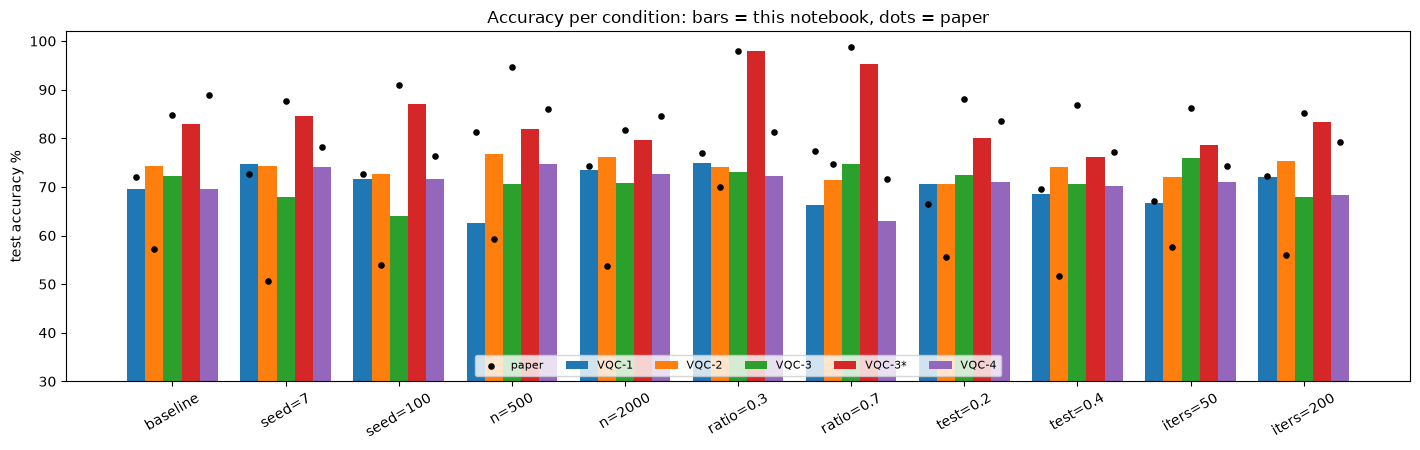

In [25]:
# Overview figure: notebook accuracy of every model in every condition (baseline + seeds + sensitivity), paper values as black markers.
keys = [("baseline", SEED)] + [("baseline", s) for s in EXTRA_SEEDS if s in (7, 100)] + [(c, SEED) for c in SENS_CONDITIONS]
labels = ["baseline"] + [f"seed={s}" for s in EXTRA_SEEDS if s in (7, 100)] + list(SENS_CONDITIONS)
PAPER_ALL = {"baseline": {m: PAPER_T5[m][0] for m in PAPER_T5}, "seed=7": {m: PAPER_T6[m][7][0] for m in PAPER_T6}, "seed=100": {m: PAPER_T6[m][100][0] for m in PAPER_T6}}
PAPER_ALL.update({c: {m: v[0] for m, v in d.items()} for c, d in PAPER_SENS.items()})
fig, ax = plt.subplots(figsize=(max(9, 1.3 * len(keys)), 4.6)); width = 0.16
for i, m in enumerate(["VQC-1", "VQC-2", "VQC-3", "VQC-3*", "VQC-4"]):
    xs = np.arange(len(keys)) + (i - 2) * width
    ax.bar(xs, [ALL[k][m]["acc"] for k in keys], width, label=m)
    ax.scatter(xs, [PAPER_ALL[l].get(m, np.nan) for l in labels], c="k", s=14, zorder=3, label="paper" if i == 0 else None)
ax.set_xticks(np.arange(len(keys))); ax.set_xticklabels(labels, rotation=30); ax.set_ylabel("test accuracy %"); ax.set_ylim(30, 102); ax.legend(ncol=6, fontsize=8, loc="lower center")
ax.set_title("Accuracy per condition: bars = this notebook, dots = paper"); plt.tight_layout(); plt.show()

## 7. Side by side with the paper: a verdict for every checkable claim

Tolerance: a number is **reproduced** if it lies within 2 accuracy/F1 points of the paper (0.02 for correlations, 0.1 for loss levels); otherwise it is **not reached** (below) or **exceeded** (above) with the gap shown.
Qualitative claims are checked on the numbers of this notebook. VQC-3\* is an extension and is not used for the verdicts of the paper's VQC-3.

In [26]:
TOL = 2.0
def verdict(paper, nb, tol=TOL):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")
V = []   # rows: claim id, description, paper, notebook, verdict, configuration
# C1 Table 5 (accuracy and F1) and C2 classical
for m, p in PAPER_T5.items():
    for k, idx, lab in [("acc", 0, "accuracy"), ("f1", 3, "F1")]:
        V.append(["C1", f"Table 5 {m} {lab}", p[idx], round(BASE[m][k], 1), verdict(p[idx], BASE[m][k])])
        if m == "VQC-3":
            V.append(["C1", f"Table 5 VQC-3* {lab}", p[idx], round(BASE["VQC-3*"][k], 1), verdict(p[idx], BASE["VQC-3*"][k])])
for m in CLASSICAL:
    V.append(["C2", f"Table 11 {m} accuracy", 100.0, round(CLASSICAL[m]["acc"], 1), verdict(100.0, CLASSICAL[m]["acc"])])
# C3 correlations
for q, pv, nv in CORR_ROWS:
    V.append(["C3", f"Fig. 4 {q}", pv, nv, verdict(pv, nv, 0.021)])
# C4 false negatives of VQC-1 / VQC-2
for m in ["VQC-1", "VQC-2"]:
    tn, fp, fn, tp = BASE[m]["cm"].ravel()
    V.append(["C4", f"{m} has many false negatives (FN > FP)", "FN > FP", f"FN={fn}, FP={fp}", "reproduced" if fn > fp else "not reached"])
# C5 loss levels (paper reads them off the loss plots; tolerance 0.1; the paper does not state the loss definition for each model)
last = lambda m: float(np.mean(BASE[m]["hist"][-5:]))
V.append(["C5", "VQC-1 final loss about 0.65 (Fig. 13)", 0.65, round(last("VQC-1"), 3), verdict(0.65, last("VQC-1"), 0.1)])
V.append(["C5", "VQC-4 final loss slightly above 0.45 (Fig. 19)", 0.45, round(last("VQC-4"), 3), verdict(0.45, last("VQC-4"), 0.1)])
V.append(["C5", "VQC-2 loss plateau about 0.4 (Fig. 15)", 0.40, round(last("VQC-2"), 3), verdict(0.40, last("VQC-2"), 0.1)])
# C6 sensitivity cells (accuracy)
for m, d in PAPER_T6.items():
    for sd, (pa, pf) in d.items():
        V.append(["C6", f"Table 6 seed {sd} {m} accuracy", pa, round(ALL[("baseline", sd)][m]["acc"], 1), verdict(pa, ALL[("baseline", sd)][m]["acc"])])
        if m == "VQC-3":
            V.append(["C6", f"Table 6 seed {sd} VQC-3* accuracy", pa, round(ALL[("baseline", sd)]["VQC-3*"]["acc"], 1), verdict(pa, ALL[("baseline", sd)]["VQC-3*"]["acc"])])
for c, d in PAPER_SENS.items():
    if (c, SEED) not in ALL: continue
    for m, (pa, pf) in d.items():
        V.append(["C6", f"{c} {m} accuracy", pa, round(ALL[(c, SEED)][m]["acc"], 1), verdict(pa, ALL[(c, SEED)][m]["acc"])])
        if m == "VQC-3":
            V.append(["C6", f"{c} VQC-3* accuracy", pa, round(ALL[(c, SEED)]["VQC-3*"]["acc"], 1), verdict(pa, ALL[(c, SEED)]["VQC-3*"]["acc"])])
# C7 robustness: mean accuracy over all conditions that were run
cond_keys = [("baseline", SEED)] + [("baseline", s) for s in (7, 100) if ("baseline", s) in ALL] + [(c, SEED) for c in SENS_CONDITIONS]
mean_acc = {m: float(np.mean([ALL[k][m]["acc"] for k in cond_keys])) for m in ["VQC-1", "VQC-2", "VQC-3", "VQC-3*", "VQC-4"]}
std_acc = {m: float(np.std([ALL[k][m]["acc"] for k in cond_keys], ddof=1)) for m in mean_acc}
best = max(["VQC-1", "VQC-2", "VQC-3", "VQC-4"], key=mean_acc.get)
V.append(["C7", "VQC-3 has the highest mean accuracy over the conditions (default lr)", "VQC-3", f"{best} ({mean_acc[best]:.1f}%)", "reproduced" if best == "VQC-3" else "not reached"])
best_s = max(["VQC-1", "VQC-2", "VQC-3*", "VQC-4"], key=mean_acc.get)
V.append(["C7", "same, with the validation-selected learning rate (VQC-3*)", "VQC-3", f"{best_s} ({mean_acc[best_s]:.1f}%)", "reproduced" if best_s == "VQC-3*" else "not reached"])
V.append(["C7", "VQC-4 is more sensitive than VQC-3 (std of accuracy over conditions)", "std(VQC-4) > std(VQC-3)", f"{std_acc['VQC-4']:.1f} vs {std_acc['VQC-3']:.1f}", "reproduced" if std_acc["VQC-4"] > std_acc["VQC-3"] else "not reached"])
# C8 VQC-4 errors are mostly anomalous samples
n_an_err = int(((D0["yte"] == 1) & (BASE["VQC-4"]["pred"] != D0["yte"])).sum()); n_no_err = int(((D0["yte"] == 0) & (BASE["VQC-4"]["pred"] != D0["yte"])).sum())
V.append(["C8", "most VQC-4 errors are anomalous samples (Figs. 21-22)", "anomalous > normal", f"anomalous={n_an_err}, normal={n_no_err}", "reproduced" if n_an_err > n_no_err else "not reached"])
VER = pd.DataFrame(V, columns=["claim", "description", "paper", "notebook", "verdict"])
VER["configuration"] = np.where(VER["description"].str.contains("VQC-3\\*"), "VQC-3* (learning rate chosen on validation data)", "primary (library-default learning rate)")
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 80):
    display(VER)
print("\nverdict counts, primary configuration (default ADAM learning rate):", VER[VER.configuration.str.startswith("primary")]["verdict"].value_counts().to_dict())
print("verdict counts, VQC-3* extension rows only                       :", VER[~VER.configuration.str.startswith("primary")]["verdict"].value_counts().to_dict())
print("verdict counts, all rows                                         :", VER["verdict"].value_counts().to_dict())
print("verdict counts by claim id  :")
display(pd.crosstab([VER["claim"], VER["configuration"].str.split(" ").str[0]], VER["verdict"]))

,claim,description,paper,notebook,verdict,configuration
0,C1,Table 5 VQC-1 accuracy,72.0,69.7,not reached,primary (library-default learning rate)
1,C1,Table 5 VQC-1 F1,70.0,67.4,not reached,primary (library-default learning rate)
2,C1,Table 5 VQC-2 accuracy,57.3,74.3,exceeded,primary (library-default learning rate)
3,C1,Table 5 VQC-2 F1,47.8,72.6,exceeded,primary (library-default learning rate)
4,C1,Table 5 VQC-3 accuracy,84.7,72.3,not reached,primary (library-default learning rate)
5,C1,Table 5 VQC-3* accuracy,84.7,83.0,reproduced,VQC-3* (learning rate chosen on validation data)
6,C1,Table 5 VQC-3 F1,84.3,70.0,not reached,primary (library-default learning rate)
7,C1,Table 5 VQC-3* F1,84.3,82.5,reproduced,VQC-3* (learning rate chosen on validation data)
8,C1,Table 5 VQC-4 accuracy,89.0,69.7,not reached,primary (library-default learning rate)
9,C1,Table 5 VQC-4 F1,88.9,68.7,not reached,primary (library-default learning rate)



verdict counts, primary configuration (default ADAM learning rate): {'not reached': 31, 'reproduced': 16, 'exceeded': 14}
verdict counts, VQC-3* extension rows only                       : {'not reached': 8, 'reproduced': 5}
verdict counts, all rows                                         : {'not reached': 39, 'reproduced': 21, 'exceeded': 14}
verdict counts by claim id  :


verdict              exceeded  not reached  reproduced
claim configuration                                   
C1    VQC-3*                0            0           2
      primary               2            6           0
C2    primary               0            0           2
C3    primary               0            0           3
C4    primary               0            0           2
C5    primary               2            0           1
C6    VQC-3*                0            8           2
      primary              10           23           7
C7    VQC-3*                0            0           1
      primary               0            2           0
C8    primary               0            0           1

In [27]:
print(f"Mean accuracy over the {len(cond_keys)} conditions run (baseline, seeds 7/100, sensitivity), and its standard deviation:")
display(pd.DataFrame({"mean accuracy %": mean_acc, "std over conditions": std_acc}).round(1).T)
print(f"\ntotal wall-clock time of this notebook run: {(time.time()-T_START)/60:.1f} min  (FAST_MODE = {FAST_MODE})")

Mean accuracy over the 11 conditions run (baseline, seeds 7/100, sensitivity), and its standard deviation:


,VQC-1,VQC-2,VQC-3,VQC-3*,VQC-4
mean accuracy %,70.1,73.8,71.0,84.4,70.8
std over conditions,3.8,2.0,3.4,6.8,3.2



total wall-clock time of this notebook run: 26.2 min  (FAST_MODE = False)


## 8. Reading the paper critically

* **The data are easy by construction and the quantum models are far from perfect.** The protocol id alone separates the two classes without a single error and so does a threshold on packets per second
  (100 +- 10 against 300 +- 40, a gap of five standard deviations of the wider class). SVM and Random Forest therefore reach 100 %, as the paper says. The interesting question is why four-qubit
  circuits with 12 to 20 trainable parameters stay at 57-90 %. The standardised features are used directly as rotation angles, and the four features are strongly correlated (r = 0.74 to 0.88), so
  the encoded states of the two classes overlap in Hilbert space; the single-observable read-out `<ZZZZ>` is a parity of all four qubits, which is a poor decision function for a problem whose class
  signal is a monotone function of each feature. The paper's explanation (optimisation difficulty, circuit depth) is plausible but not tested against an alternative such as another observable or a rescaling to [0, pi].
* **A single run on 300 test points is a noisy number.** One test sample is 0.33 accuracy points; the binomial standard error at 80 % accuracy is 2.3 points, and optimiser randomness (initial weights, SPSA perturbations, shot noise)
  adds more. The multi-seed table above shows spreads of several points for every model, so claims such as "VQC-4 (89.0 %) beats VQC-3 (84.7 %)" at the baseline and
  the cell-by-cell rankings of Tables 6-10 are within the noise unless they are repeated over seeds. The paper itself reports that VQC-3 and VQC-4 swap places between conditions.
* **Unspecified hyper-parameters decide the ranking.** The ADAM learning rate is not given; with the library default 0.001, 100 iterations move the weights by at most about 0.1 per parameter, whereas a larger rate changes
  VQC-3 by double-digit accuracy points (see the learning-rate table and the VQC-3\* row). Similarly the label convention for `EstimatorQNN` (-1/+1 vs 0/1 targets), the observable, the initial point and the ansatz entanglement are not stated.
  A reproduction can therefore agree or disagree with the paper by choice of these defaults alone.
* **"Macro-averaged" metrics are weighted.** In Table 5 recall equals accuracy for every model, which holds only for support-weighted recall. The notebook uses weighted averages to compare like with like.
* **Sensitivity "to the test size" mixes two effects**: changing `test_size` changes both the amount of training data and the noise of the evaluation. The paper explains accuracy rises at 500 samples by the smaller evaluation set;
  the standard error argument above suggests that it is mostly noise in the evaluation of one run.
* **No quantum advantage claim is made**, and none could be: the problem is solved perfectly by two classical models in milliseconds. The paper's conclusion is cautious in the same way.

## 9. Exercises

1. **A better read-out.** Replace the parity observable `ZZZZ` by `Z` on a single qubit (`observables=SparsePauliOp("IIIZ")`) or by the mean of the four single-qubit `Z` terms. Does VQC-1 stay near 72 %? Use `FastCircuit.probs` to compute the new expectation.
2. **Rescale the angles.** Map the standardised features to [0, pi] with a `MinMaxScaler` fitted on the training split (as in the other notebooks of this repository) before the feature maps. Which of the four models improves most?
3. **Learning rate and iterations.** Plot the test accuracy of VQC-3 against the ADAM learning rate (0.0003 ... 0.3) for 50, 100 and 200 iterations. Is the paper's remark that VQC-3 "converges at about 40 iterations" true for any learning rate?
4. **Error bars for Tables 6-10.** Run each condition for ten seeds and report mean +- std. How many of the 40 accuracy cells of the paper are inside the one-standard-deviation band of your runs?
5. **Make the problem hard.** Remove the protocol feature and bring the two packet-rate distributions closer (for example N(150, 40^2) against N(200, 40^2)). Do SVM and Random Forest still reach 100 %? Do the quantum classifiers follow them down or stay put?

## Summary of this run (written after execution; the code and outputs above are untouched)

* **Data recipe and classical baselines reproduce exactly.** The generated data have the paper's structure (feature correlations 0.86 / 0.85 / 0.86 against 0.86 / 0.87 / 0.88), and SVM (RBF) and Random Forest classify every test point correctly in every run (100 %), as in Table 11.
* **The quantum numbers of Table 5 are not reproduced with library defaults.** With seed 42 the four models give 69.7 / 74.3 / 72.3 / 69.7 % accuracy (VQC-1 / 2 / 3 / 4) against the paper's 72.0 / 57.3 / 84.7 / 89.0 %. Over six seeds the means are 72.6 +- 2.9, 72.1 +- 3.6, 69.2 +- 4.5 and 72.4 +- 1.6 %, so in this reproduction the four architectures are statistically indistinguishable except VQC-3, and the paper's ranking (VQC-4 best at baseline, VQC-2 worst) is not seen. VQC-1 is the one model that matches (69.7-76.3 % over seeds against 72 %).
* **The ADAM learning rate matters.** With the learning rate chosen on a validation split of the training data (0.1, "VQC-3*"), VQC-3 reaches 83.0 % at the baseline (paper 84.7 %), 85.9 +- 3.3 % over six seeds, 98.0 % at anomaly ratio 0.3 (paper 98.0 %) and is by far the most robust quantum model, as the paper says. This supports the paper's qualitative claim that the simple ZFeatureMap with a deeper RealAmplitudes ansatz and ADAM is best, but it needs a learning rate the paper does not report.
* **Qualitative findings that are reproduced:** VQC-1 and VQC-2 miss many anomalies (false negatives far outnumber false positives), most VQC-4 errors are anomalous samples classified as normal, and the quantum classifiers stay far below the classical ones. **Not reproduced:** the strong class bias of VQC-2 towards "normal" in the paper (57.3 % at the baseline) and its reversal at anomaly ratio 0.7; the paper's accuracy gains of VQC-3/VQC-4 with 500 samples (they are within the run-to-run noise here).
* The verdict table in Section 7 gives every cell; the counts there (primary configuration and the VQC-3* extension) are the ones to quote.